# Matplotlib Detailed Guide: Data Visualization & Plotting

[Matplotlib](https://matplotlib.org/) is Python's foundational 2D plotting library. It provides both a state-based procedural interface (`pyplot`, modeled after MATLAB) and an Object-Oriented (OO) API that gives complete programmatic control over every visual element on a figure canvas.

---

### What This Notebook Covers:
0. **Importing & Fundamentals**: Pyplot vs Object-Oriented APIs, Jupyter display mechanics, suppressing textual output, and the canonical 5-step workflow.
1. **NumPy Array Plotting**: Line plots ($y = x^2$), scatter plots ($y = e^x$), vertical and horizontal bar charts, histograms, and multi-axes subplot layouts.
2. **Pandas Integration**: Direct Series and DataFrame plotting, cumulative financial time-series visualization, data cleaning for visualization, and grouped bar charts.
3. **Advanced Object-Oriented Visualizations**: Complex multi-variable plots, data-driven categorical coloring, dynamic legend extraction with `legend_elements()`, and statistical threshold reference lines (`axhline`).
4. **Subplot Layouts & Shared Coordinate Systems**: Multi-panel dashboards with shared horizontal axes (`sharex=True`) and figure-level super titles (`fig.suptitle`).
5. **Plot Customization & Aesthetics**: Style sheets (`plt.style.use`), typography, legend placement, colormaps (`cmap`), and axis boundary controls (`xlim`, `ylim`).
6. **Saving & Exporting**: Exporting high-resolution graphics (`fig.savefig`) across vector and raster formats with publication-quality DPI and tight bounding boxes.
7. **Comprehensive Matplotlib Cheat Sheet**: Complete reference table summarizing core methods, parameter defaults, and visual effects.

## 0. Importing Matplotlib

By universal community convention:
- The base package is imported as `matplotlib`.
- The stateful interface submodule `matplotlib.pyplot` is imported under the alias `plt`.

In [81]:
import matplotlib
import matplotlib.pyplot as plt

print("Matplotlib version:", matplotlib.__version__)

Matplotlib version: 3.11.2


### 0.1 The Pyplot Interface & Canvas Generation

Calling `plt.plot()` without any arguments initializes an empty Figure canvas and coordinate Axes.
- In Jupyter Notebooks, evaluating an expression that returns a Matplotlib object outputs both the Python object representation (e.g., `[]` or `<Figure ...>`) and renders the canvas graphic below the cell.

[]

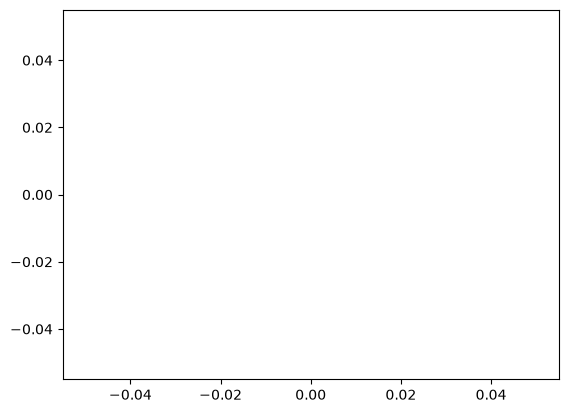

In [82]:
# create a simple plot
plt.plot()

#### Suppressing Output Text with a Semicolon (`;`)
Adding a semicolon `;` at the end of the final line in a Jupyter cell suppresses the textual return value of the expression, rendering **only** the visual canvas graphic cleanly.

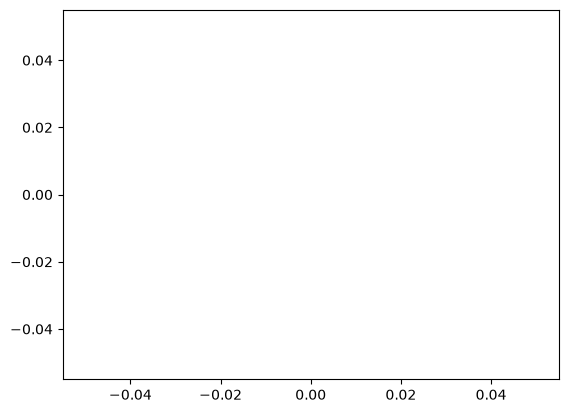

In [83]:
# with the semi-colon
plt.plot();

#### Explicit Display with `plt.show()`
`plt.show()` instructs the Matplotlib rendering backend to flush and display all pending canvas figures.
- In standalone Python scripts (`.py`), plots do not appear until `plt.show()` is called.
- In Jupyter Notebooks with inline rendering, calling `plt.show()` displays the plot and closes the figure buffer, discarding the textual object representation.

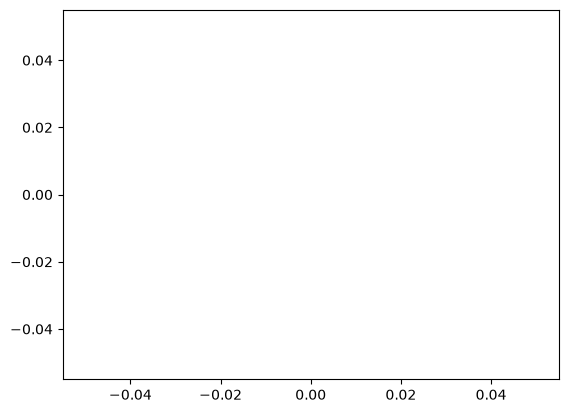

In [84]:
plt.plot()
plt.show()

### 0.2 Single-Sequence Line Plotting

**Syntax:** `plt.plot(y)`

**Behavior:**
When only one 1D array or list is passed:
- The provided values are assigned as the **y-coordinates** (`[1, 2, 3, 4]`).
- The **x-coordinates** are automatically generated as zero-indexed integers: `0, 1, 2, ..., N-1` (i.e. `[0, 1, 2, 3]`).

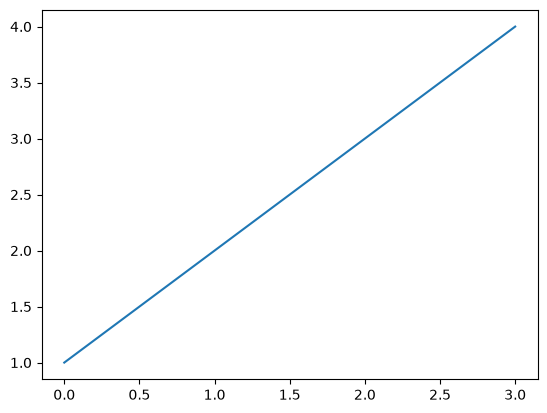

In [85]:
# simple line plot
plt.plot([1, 2, 3, 4]);

### 0.3 Dual-Sequence (X, Y) Line Plotting

**Syntax:** `plt.plot(x, y)`

**Parameters & Requirements:**
- **`x`**: Sequence of coordinates along the horizontal axis.
- **`y`**: Sequence of coordinates along the vertical axis.
- Both sequences must have identical lengths; otherwise a `ValueError` is raised.

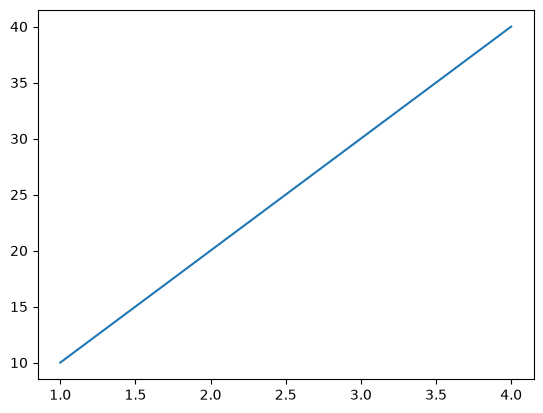

In [86]:
# create some data
x = [1, 2, 3, 4]        # x-axis values
y = [10, 20, 30, 40]    # y-axis values

plt.plot(x, y);

## 1. Pyplot API vs Object-Oriented (OO) API

Matplotlib provides two distinct paradigms for creating visualizations:
1. **Pyplot (MATLAB-style / Procedural)**: Uses `plt.<function>()` calls that implicitly target the "current active" figure and axes. While fast for simple interactive tests, it becomes error-prone and unmanageable when building complex multi-axes figures.
2. **Object-Oriented (OO) API**: Explicitly instantiates `Figure` and `Axes` objects and calls methods directly on them (`ax.plot()`, `ax.set_title()`). **This is the recommended standard across data science and machine learning.**

---

### Anatomy of a Matplotlib Figure
```
┌─────────────────────────────────────────────────────────────┐  <-- Figure (fig): Overall canvas
│  Figure Title (fig.suptitle)                                │
│                                                             │
│   ┌──────────────────────────────────────────────────────┐  │
│   │ Axes Title (ax.set_title)                            │  │
│ Y │                                            Legend    │  │
│   │                                           ┌────────┐ │  │
│ A │   * Marker (x, y)                         │ - Data │ │  │  <-- Axes (ax): Plotting area
│ x │    \                                      └────────┘ │  │
│ i │     \___ Line (ax.plot)                              │  │
│ s │                                                      │  │
│   │                                       Threshold Line │  │
│   │ ------------------------------------- (ax.axhline)   │  │
│   └──────────────────────────────────────────────────────┘  │
│                 X Axis (ax.set_xlabel, ticks, ticklabels)   │
└─────────────────────────────────────────────────────────────┘
```

- **Figure (`fig`)**: The overarching canvas that holds all visual elements (axes, titles, legends, colorbars).
- **Axes (`ax`)**: The actual plot coordinate system (bounding box with x-axis and y-axis) where data lines, bars, and points are drawn.
- **Axis (`ax.xaxis`, `ax.yaxis`)**: The number-lines that set coordinate limits and generate tick marks and labels.
- **Artist**: Every element rendered on the canvas (lines, text, patches) is a Matplotlib Artist.

---

### Method 1A: Creating Axes with `fig.add_subplot()`
Creates a top-level canvas using `plt.figure()` and attaches an Axes using `fig.add_subplot()`:

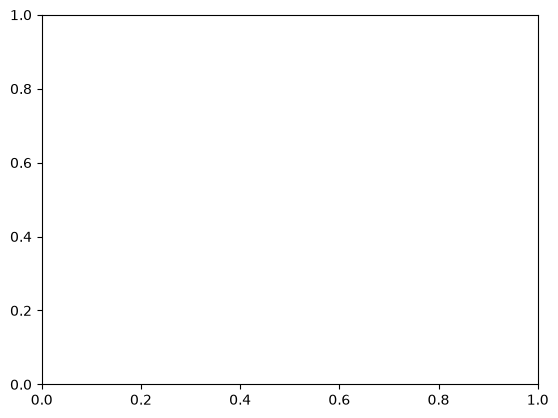

In [87]:
# Creating a plot with object-oriented approach
fig = plt.figure()  # Create a new figure
ax = fig.add_subplot()  # Add a subplot to the figure
plt.show();

### Method 1B: Precise Placement with `fig.add_axes([left, bottom, width, height])`

**Method:** `fig.add_axes([left, bottom, width, height])`

**Parameters:**
- Takes a 4-element list specifying normalized figure coordinates:
  - **`left`**: Horizontal offset from figure's left edge (`0.0` to `1.0`).
  - **`bottom`**: Vertical offset from figure's bottom edge (`0.0` to `1.0`).
  - **`width`**: Width of the axes as a fraction of total figure width.
  - **`height`**: Height of the axes as a fraction of total figure height.
- *Note:* Passing `[1, 1, 1, 1]` places the axes outside standard normalized bounds, demonstrating manual positioning.

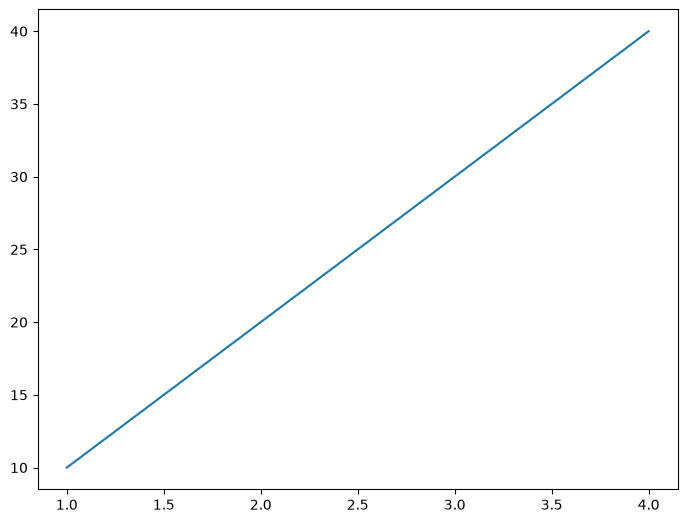

In [88]:
# Add some data to our previous plot
fig = plt.figure()  # Create a new figure
ax = fig.add_axes([1, 1, 1, 1])  # Add axes to the figure
ax.plot(x, y)  # Plot data on the axes
plt.show();

### Method 1C: The Standard OO Approach (`plt.subplots()`)

**Function:** `plt.subplots(nrows=1, ncols=1, figsize=None)`

**Why this is the standard:**
`plt.subplots()` conveniently creates both the `Figure` and one or more `Axes` simultaneously and returns them as a clean tuple `(fig, ax)`, eliminating boilerplate code.

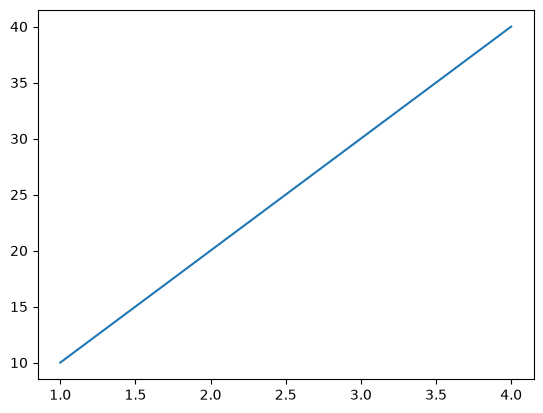

In [89]:
# Create a figure and multiple potential Axes and add some data
fig, ax = plt.subplots()  # Create a figure and a set of subplots
ax.plot(x, y);  # Plot data on the axes

Inspecting the concrete Python types confirming the Object-Oriented design:
- `fig` $\rightarrow$ `matplotlib.figure.Figure`
- `ax` $\rightarrow$ `matplotlib.axes._axes.Axes`

In [90]:
# This is where object-oriented name comes from
type(fig), type(ax)

(matplotlib.figure.Figure, matplotlib.axes._axes.Axes)

### 1.3 The Canonical 5-Step Matplotlib Workflow

Every structured Matplotlib script follows 5 modular steps:
1. **Prepare Data**: Prepare Python lists, NumPy arrays, or Pandas DataFrames.
2. **Setup Plot**: Instantiate `fig, ax = plt.subplots(figsize=(width, height))` with dimensions in inches.
3. **Plot Data**: Call plotting methods on `ax` (`ax.plot`, `ax.scatter`, `ax.bar`, etc.).
4. **Customize Plot**: Configure titles, axis labels, legends, tick marks, and limits using `ax.set()`.
5. **Save & Show**: Export the canvas with `fig.savefig()` before calling `plt.show()` (saving after `plt.show()` in scripts can produce a blank image).

#### Style Parameters for `ax.plot()`:
- **`color="red"`**: Sets line stroke color.
- **`linewidth=2`**: Line thickness in points.
- **`linestyle="-"`**: Solid line (`'-'`), dashed (`'--'`), dotted (`':'`), or dash-dot (`'-.'`).
- **`marker="o"`**: Symbol at each data coordinate (`'o'` circle, `'s'` square, `'^'` triangle).
- **`markersize=8`**: Point symbol diameter in points.
- **`markerfacecolor="blue"`**: Interior fill color of the marker symbol.
- **`markeredgewidth=2`**: Border stroke thickness around markers.

/tmp/ipykernel_63157/1949128489.py:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()  # Display the figure


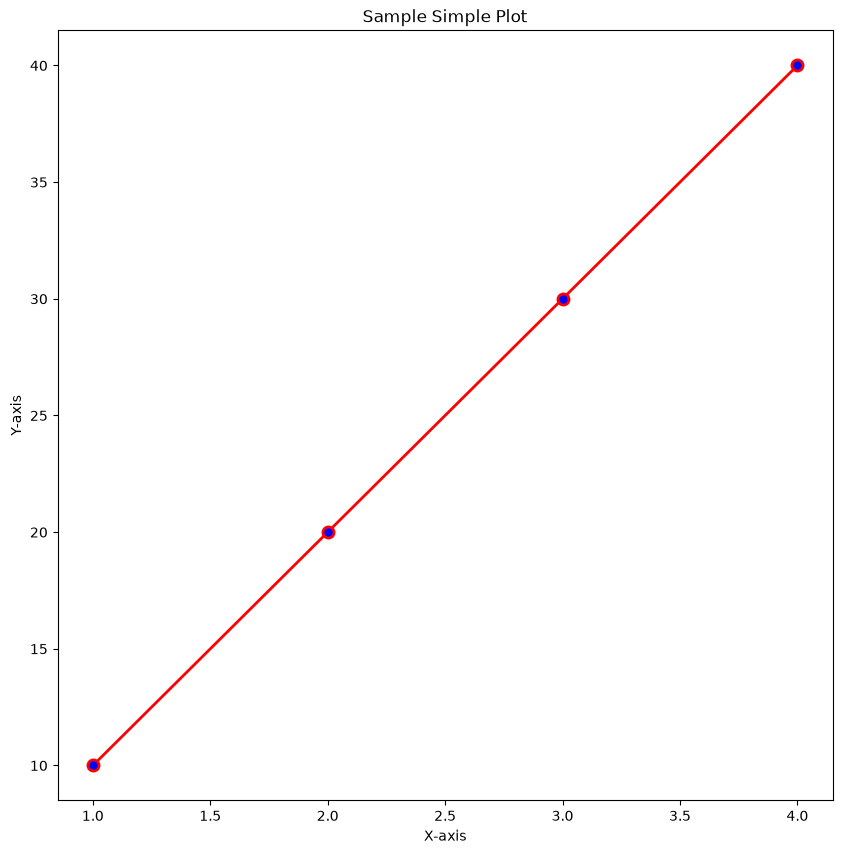

In [91]:
# A matplotlib workflow

# Import and get matplotlib ready

# 1. Prepare the data
x = [1, 2, 3, 4]
y = [10, 20, 30, 40]

# 2. Setup plot (Figure and Axes)
fig, ax = plt.subplots(figsize=(10,10))  # Create a figure and a set of subplots with specified size

# 3. Plot data
ax.plot(x, y, color="red", linewidth=2, linestyle="-", marker="o", markersize=8, markerfacecolor="blue", markeredgewidth=2)

# 4. Customize plot
ax.set(title="Sample Simple Plot", xlabel="X-axis", ylabel="Y-axis")

# 5. Save & show (you save the figure first before showing it)
fig.savefig("data/sample-plot.png")  # Save the figure to a file
fig.show()  # Display the figure

## 2. Making Common Plots Using NumPy Arrays

NumPy arrays are the foundational data structure for numerical data in Python. Matplotlib is natively optimized to accept NumPy 1D and 2D arrays across all plotting functions.

In [92]:
import numpy as np

### 2.1 Generating Continuous Data with `np.linspace()`

**Function:** `np.linspace(start, stop, num=50)`
- **`start=0`**, **`stop=10`**: Interval boundaries.
- **`num=100`**: Generates 100 evenly spaced values across $[0, 10]$, providing smooth coordinate resolution for mathematical curves.

In [93]:
# Create an array of 1000 random numbers from a normal distribution
x = np.linspace(0, 10, 100)  # Create an array of 1000 points between 0 and 10
x[:50]      # The first 50 values of x

array([0.        , 0.1010101 , 0.2020202 , 0.3030303 , 0.4040404 ,
       0.50505051, 0.60606061, 0.70707071, 0.80808081, 0.90909091,
       1.01010101, 1.11111111, 1.21212121, 1.31313131, 1.41414141,
       1.51515152, 1.61616162, 1.71717172, 1.81818182, 1.91919192,
       2.02020202, 2.12121212, 2.22222222, 2.32323232, 2.42424242,
       2.52525253, 2.62626263, 2.72727273, 2.82828283, 2.92929293,
       3.03030303, 3.13131313, 3.23232323, 3.33333333, 3.43434343,
       3.53535354, 3.63636364, 3.73737374, 3.83838384, 3.93939394,
       4.04040404, 4.14141414, 4.24242424, 4.34343434, 4.44444444,
       4.54545455, 4.64646465, 4.74747475, 4.84848485, 4.94949495])

### 2.2 Line Plot (`ax.plot`)

Plots continuous curves and trends. Here, plotting the parabola $y = x^2$:
- Visualizes quadratic growth over the domain $x \in [0, 10]$.

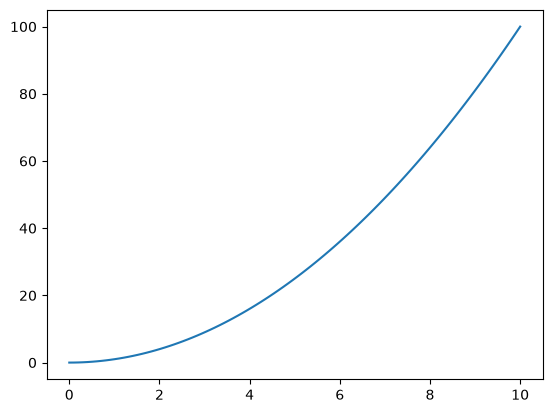

In [94]:
# The default plot is line
fig, ax = plt.subplots()
ax.plot(x, x**2);

### 2.3 Scatter Plot (`ax.scatter`)

**Method:** `ax.scatter(x, y, s=None, c=None, marker=None, alpha=None)`

**Parameters & Effects:**
- **`x`, `y`**: Coordinate sequences. Here plotting the exponential curve $y = e^x$.
- **`s`**: Size of marker points (in points$^2$). Default is ~36.
- **`c`**: Marker color or array of numeric values for colormapping.
- **`alpha`**: Opacity from `0.0` (invisible) to `1.0` (opaque). Useful for revealing point density when observations overlap.
- **Difference from `ax.plot()`**: `ax.scatter()` treats each point as an independent graphic element, enabling point-by-point variation in color and size.

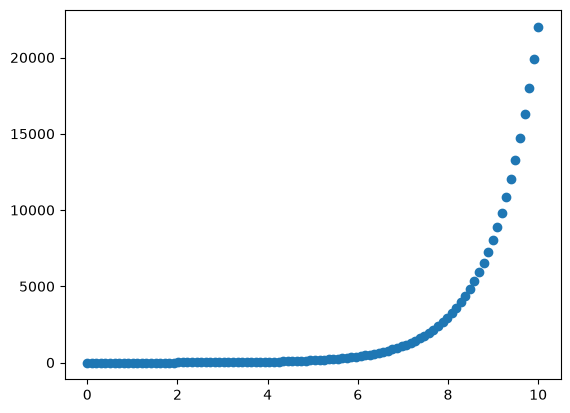

In [95]:
# Creating a scatter plot
fig, ax = plt.subplots()
ax.scatter(x, np.exp(x));

### 2.4 Vertical Bar Chart (`ax.bar`)

**Method:** `ax.bar(x, height, width=0.8, color=None)`

**Parameters & Effects:**
- **`x`**: Categorical labels or x-axis positions (e.g., dictionary keys `nut_butter_prices.keys()`).
- **`height`**: Bar heights corresponding to numerical magnitudes (e.g., `nut_butter_prices.values()`).
- **`width`**: Width of the bars (default is `0.8`).
- Best suited for discrete categorical comparisons with short category names.

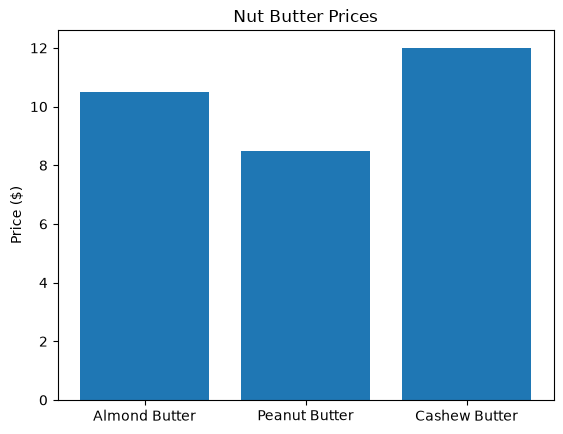

In [96]:
# Creating a bar plot
nut_butter_prices = {"Almond Butter": 10.50, "Peanut Butter": 8.50, "Cashew Butter": 12.00}

fig, ax = plt.subplots()
ax.bar(nut_butter_prices.keys(), nut_butter_prices.values())
ax.set(title="Nut Butter Prices", ylabel="Price ($)");

### 2.5 Horizontal Bar Chart (`ax.barh`)

**Method:** `ax.barh(y, width, height=0.8, color=None)`

**Parameters & Effects:**
- **`y`**: Categorical labels placed along the vertical axis.
- **`width`**: Horizontal length of each bar representing the numerical value.
- **When to use:** Horizontal bar charts are ideal when category labels are long or numerous, preventing label truncation or diagonal overlapping on the x-axis.

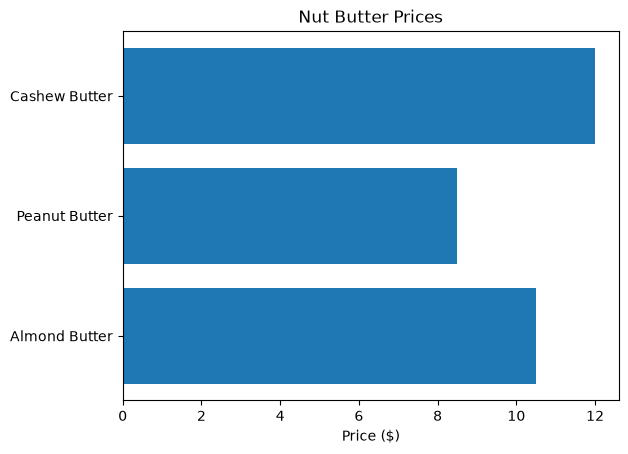

In [97]:
fig, ax = plt.subplots()
ax.barh(nut_butter_prices.keys(), nut_butter_prices.values())
ax.set(title="Nut Butter Prices", xlabel="Price ($)");


### 2.6 Histogram Plot (`ax.hist`)

**Method:** `ax.hist(x, bins=None, range=None, density=False, color=None, alpha=None)`

**Parameters & Effects:**
- **`x`**: 1D array of continuous numeric observations.
- **`bins`**: Number of equal-width intervals into which the data range is split (e.g., `bins=30`).
  - Too few bins oversimplifies and hides distribution patterns.
  - Too many bins creates noisy, jagged histograms.
- **`alpha=0.7`**: 70% opacity, allowing grid lines and overlapping distributions to remain visible.
- Demonstrates the empirical bell-curve shape of a standard normal distribution $\mathcal{N}(0, 1)$.

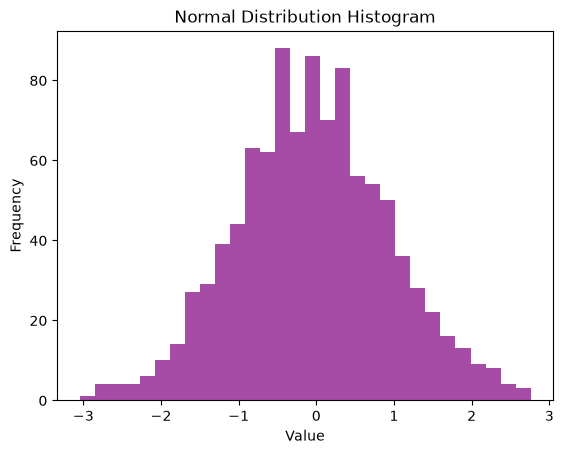

In [98]:
# Plotting a histogram

# Create a random normal distribution of 1000 points
np.random.seed(0)  # Set the random seed for reproducibility
x = np.random.randn(1000)  # Generate 1000 random numbers from a normal distribution

fig, ax = plt.subplots()
ax.hist(x, bins=30, color="purple", alpha=0.7)
ax.set(title="Normal Distribution Histogram", xlabel="Value", ylabel="Frequency");

### 2.7 Creating Multiple Subplots on a Single Figure

`plt.subplots(nrows, ncols)` generates a multi-panel grid. There are two primary techniques to address individual sub-axes:

#### Option 1: Tuple Unpacking into Explicit Variables
Unpack the returned 2D array directly into named variables `((ax0, ax1), (ax2, ax3))`:
- Each variable directly maps to a distinct quadrant: `ax0` (top-left), `ax1` (top-right), `ax2` (bottom-left), `ax3` (bottom-right).
- Highly readable when each subplot visualizes fundamentally different plot types.

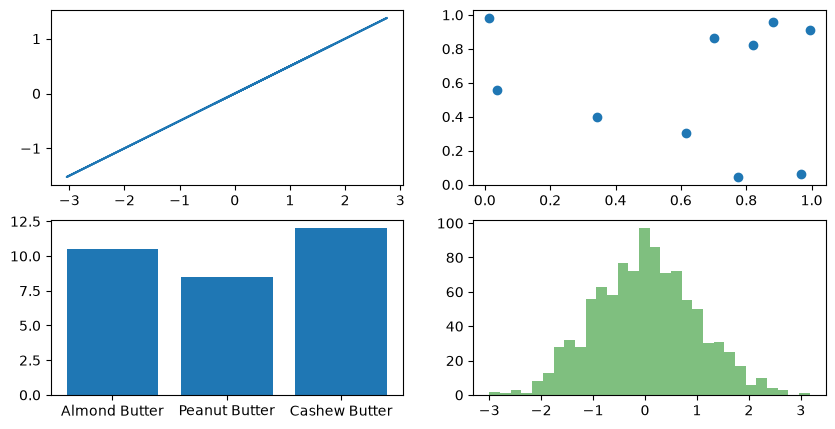

In [99]:
# Option 1: Create 4 subplots with each Axes having its own variable name
fig, ((ax0, ax1), (ax2, ax3)) = plt.subplots(nrows=2, ncols=2, figsize=(10, 5))

# Plot data to each Axes
ax0.plot(x, x/2);
ax1.scatter(np.random.random(10), np.random.random(10));
ax2.bar(nut_butter_prices.keys(), nut_butter_prices.values());
ax3.hist(np.random.randn(1000), bins=30, color="green", alpha=0.5);

#### Option 2: 2D Array Matrix Indexing
When assigning `fig, ax = plt.subplots(nrows=2, ncols=2)`, `ax` is a 2D NumPy array of shape `(2, 2)`:
- Access subplots via matrix indexing: `ax[row_index, col_index]`.
- Essential when programmatically iterating over subplots in nested loops (`for r in range(nrows): ...`).

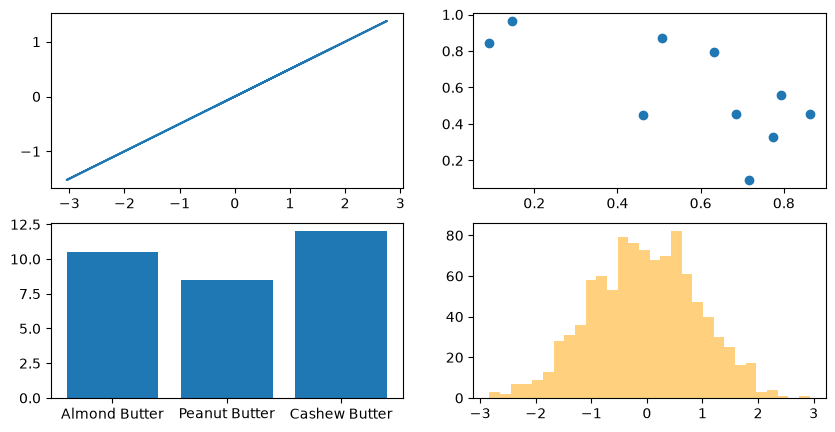

In [100]:
# Option 2: Create 4 subplots with a single Axes variable name and index into the array of Axes
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(10, 5))

# Index into the array of Axes and plot data
ax[0, 0].plot(x, x/2);
ax[0, 1].scatter(np.random.random(10), np.random.random(10));
ax[1, 0].bar(nut_butter_prices.keys(), nut_butter_prices.values());
ax[1, 1].hist(np.random.randn(1000), bins=30, color="orange", alpha=0.5);

## 3. Plotting Data Directly with Pandas

Pandas provides convenient wrapper methods (`df.plot()`, `df.plot.bar()`, `df.plot.hist()`) built directly on top of Matplotlib. This allows immediate visualization of DataFrames and Series without manually extracting NumPy arrays.

In [101]:
import pandas as pd

Loading the automotive sales dataset from CSV:
- **`index_col=0`**: Uses the first column (CSV row index) as DataFrame index.

In [102]:
car_sales = pd.read_csv("data/car-sales.csv", index_col=0)  # Load the car sales dataset and set the first column as the index
car_sales

,Make,Colour,Odometer (KM),Doors,Price
0,Toyota,White,150043,4,"$4,000.00"
1,Honda,Red,87899,4,"$5,000.00"
2,Toyota,Blue,32549,3,"$7,000.00"
3,BMW,Black,11179,5,"$22,000.00"
4,Nissan,White,213095,4,"$3,500.00"
5,Toyota,Green,99213,4,"$4,500.00"
6,Honda,Blue,45698,4,"$7,500.00"
7,Honda,Blue,54738,4,"$7,000.00"
8,Toyota,White,60000,4,"$6,250.00"
9,Nissan,White,31600,4,"$9,700.00"


### 3.1 Time Series Visualization & Cumulative Growth

Creating a synthetic 1,000-day stationary time series:
- **`pd.date_range("1/1/2024", periods=1000)`**: Generates a continuous daily timestamp index from Jan 1, 2024.
- **`np.random.randn(1000)`**: Draws 1,000 random values from a standard normal distribution.

In [103]:
# Some dummy data
ts = pd.Series(np.random.randn(1000), index=pd.date_range("1/1/2024", periods=1000))

ts # Display the time series

2024-01-01   -0.625943
2024-01-02    0.472328
2024-01-03    0.966306
2024-01-04    0.210231
2024-01-05   -0.685097
                ...   
2026-09-22    0.186979
2026-09-23    0.503779
2026-09-24    1.910343
2026-09-25    0.553781
2026-09-26   -0.587481
Freq: D, Length: 1000, dtype: float64

#### Computing Cumulative Sums (`.cumsum()`)
`.cumsum()` calculates running total accumulation:
$$S_k = \sum_{i=1}^k x_i$$
Simulates integrated time series, random walks, or cumulative revenue over time.

In [104]:
# Add up the values commutatively to create a cumulative sum
ts.cumsum()

2024-01-01    -0.625943
2024-01-02    -0.153615
2024-01-03     0.812691
2024-01-04     1.022922
2024-01-05     0.337825
                ...    
2026-09-22   -16.051366
2026-09-23   -15.547587
2026-09-24   -13.637244
2026-09-25   -13.083463
2026-09-26   -13.670945
Freq: D, Length: 1000, dtype: float64

Plotting the raw stationary daily fluctuations:
- By default, Pandas maps the Series `index` to the x-axis and values to the y-axis.

<Axes: >

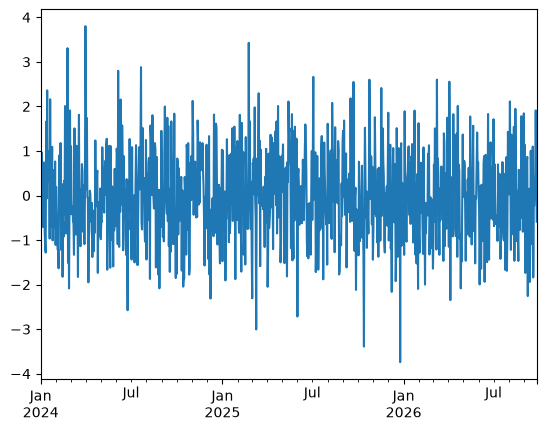

In [105]:
# Plot the time series
ts.plot()

Plotting the cumulative sum reveals the macro trajectory and long-term trend:

<Axes: >

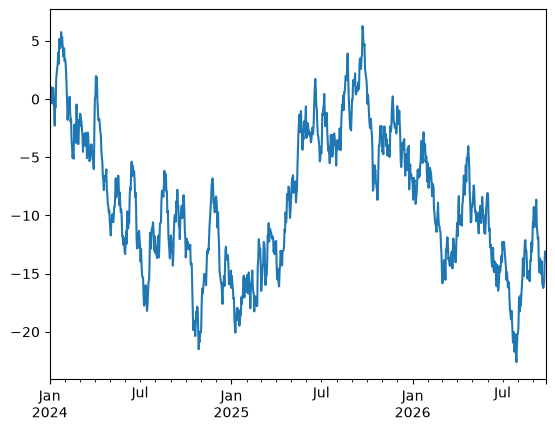

In [106]:
# plot the cumulative sum of the time series
ts.cumsum().plot()

### 3.2 Real-World Data Cleaning for Plotting

Inspecting `car_sales`: Notice the `Price` column is formatted as string text with dollar signs (`$`), commas (`,`), and trailing decimals (`.00`). Strings cannot be plotted on numeric continuous axes and must be cleaned first.

In [107]:
car_sales

,Make,Colour,Odometer (KM),Doors,Price
0,Toyota,White,150043,4,"$4,000.00"
1,Honda,Red,87899,4,"$5,000.00"
2,Toyota,Blue,32549,3,"$7,000.00"
3,BMW,Black,11179,5,"$22,000.00"
4,Nissan,White,213095,4,"$3,500.00"
5,Toyota,Green,99213,4,"$4,500.00"
6,Honda,Blue,45698,4,"$7,500.00"
7,Honda,Blue,54738,4,"$7,000.00"
8,Toyota,White,60000,4,"$6,250.00"
9,Nissan,White,31600,4,"$9,700.00"


Stripping currency symbols and decimal cents from `Price`:
- **`.str.replace('[\$\,\.]', '', regex=True)`**: Regex removes `$`, `,`, and `.`.
- **`.str[:-2]`**: Removes the last two digits representing cents, leaving integer whole dollar amounts.

In [108]:
# Remove the price column symbols and last 2 digits (cents) from the Price column
car_sales["Price"] = car_sales["Price"].str.replace('[\$\,\.]', '', regex=True).str[:-2]
car_sales

<>:2: SyntaxWarning: invalid escape sequence '\$'
<>:2: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_63157/4056408802.py:2: SyntaxWarning: invalid escape sequence '\$'
  car_sales["Price"] = car_sales["Price"].str.replace('[\$\,\.]', '', regex=True).str[:-2]


,Make,Colour,Odometer (KM),Doors,Price
0,Toyota,White,150043,4,4000
1,Honda,Red,87899,4,5000
2,Toyota,Blue,32549,3,7000
3,BMW,Black,11179,5,22000
4,Nissan,White,213095,4,3500
5,Toyota,Green,99213,4,4500
6,Honda,Blue,45698,4,7500
7,Honda,Blue,54738,4,7000
8,Toyota,White,60000,4,6250
9,Nissan,White,31600,4,9700


Adding a sequential transaction `Date` column:
- **`periods=len(car_sales)`**: Generates exactly 10 daily timestamps matching the number of rows.

In [109]:
# Add a date column
car_sales["Date"] = pd.date_range("1/1/2024", periods=len(car_sales))
car_sales

,Make,Colour,Odometer (KM),Doors,Price,Date
0,Toyota,White,150043,4,4000,2024-01-01
1,Honda,Red,87899,4,5000,2024-01-02
2,Toyota,Blue,32549,3,7000,2024-01-03
3,BMW,Black,11179,5,22000,2024-01-04
4,Nissan,White,213095,4,3500,2024-01-05
5,Toyota,Green,99213,4,4500,2024-01-06
6,Honda,Blue,45698,4,7500,2024-01-07
7,Honda,Blue,54738,4,7000,2024-01-08
8,Toyota,White,60000,4,6250,2024-01-09
9,Nissan,White,31600,4,9700,2024-01-10


Converting the cleaned string prices to integer type (`int`):
- Essential so Matplotlib treats prices as continuous numerical values rather than categorical labels.

In [110]:
# Convert the Price column to integers
car_sales["Price"] = car_sales["Price"].astype(int)

Computing cumulative revenue across consecutive car sales:

In [111]:
# Make a total sales column
car_sales["Total Sales"] = car_sales["Price"].cumsum()
car_sales

,Make,Colour,Odometer (KM),Doors,Price,Date,Total Sales
0,Toyota,White,150043,4,4000,2024-01-01,4000
1,Honda,Red,87899,4,5000,2024-01-02,9000
2,Toyota,Blue,32549,3,7000,2024-01-03,16000
3,BMW,Black,11179,5,22000,2024-01-04,38000
4,Nissan,White,213095,4,3500,2024-01-05,41500
5,Toyota,Green,99213,4,4500,2024-01-06,46000
6,Honda,Blue,45698,4,7500,2024-01-07,53500
7,Honda,Blue,54738,4,7000,2024-01-08,60500
8,Toyota,White,60000,4,6250,2024-01-09,66750
9,Nissan,White,31600,4,9700,2024-01-10,76450


### 3.3 DataFrame Line Plot with Explicit Axis Columns

**Method:** `df.plot(x="ColA", y="ColB")`

**Parameters & Effects:**
- **`x="Date"`**: Column mapped to the horizontal axis.
- **`y="Total Sales"`**: Column mapped to the vertical axis.

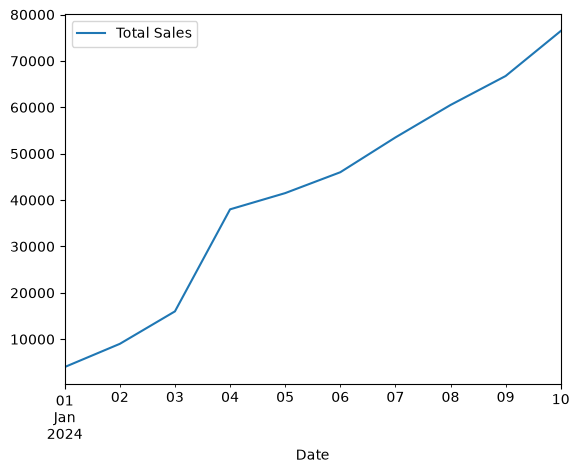

In [112]:
car_sales.plot(x="Date", y="Total Sales");

### 3.4 DataFrame Scatter Plot

**Method:** `df.plot(x=..., y=..., kind="scatter")`

**Parameters & Effects:**
- **`kind="scatter"`**: Configures a scatter plot geometry.
- Visualizes relationship between vehicle mileage (`Odometer (KM)`) and transaction value (`Price`).

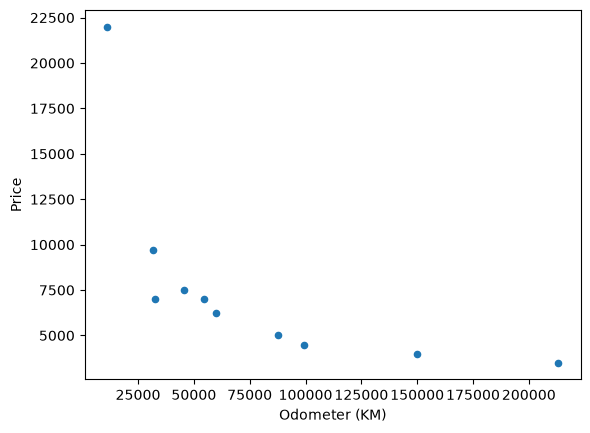

In [113]:
# Plot a scatter plot
car_sales.plot(x="Odometer (KM)", y="Price", kind="scatter");

### 3.5 Grouped Bar Charts from DataFrames

Generating a $10 \times 4$ uniform random matrix:

In [114]:
# Create a 10 random samples across 4 columns
x = np.random.rand(10, 4)
x

array([[0.34216208, 0.73123268, 0.70765973, 0.99833004],
       [0.11187205, 0.00212539, 0.74778446, 0.56877692],
       [0.69087413, 0.75352503, 0.49350655, 0.35653453],
       [0.77037589, 0.38012993, 0.62219227, 0.89340603],
       [0.15839147, 0.00890616, 0.25675661, 0.79747194],
       [0.56682564, 0.94616086, 0.5478741 , 0.26578138],
       [0.7658853 , 0.65755039, 0.82068336, 0.66799848],
       [0.45194901, 0.27708267, 0.05560046, 0.30793625],
       [0.04625848, 0.43002707, 0.22579991, 0.70364761],
       [0.22017853, 0.08143184, 0.83879728, 0.06003286]])

Constructing a DataFrame with 4 numeric columns:

In [115]:
# Turn into a DataFrame
df = pd.DataFrame(x, columns=["a", "b", "c", "d"])
df

,a,b,c,d
0,0.342162,0.731233,0.707660,0.998330
1,0.111872,0.002125,0.747784,0.568777
2,0.690874,0.753525,0.493507,0.356535
3,0.770376,0.380130,0.622192,0.893406
4,0.158391,0.008906,0.256757,0.797472
5,0.566826,0.946161,0.547874,0.265781
6,0.765885,0.657550,0.820683,0.667998
7,0.451949,0.277083,0.055600,0.307936
8,0.046258,0.430027,0.225800,0.703648
9,0.220179,0.081432,0.838797,0.060033


#### Method 1: Using the `.plot.bar()` Accessor
- Groups all 4 column values into side-by-side vertical bars for each row index (`0` through `9`).
- Automatically creates a distinct color per column and includes an explanatory legend.

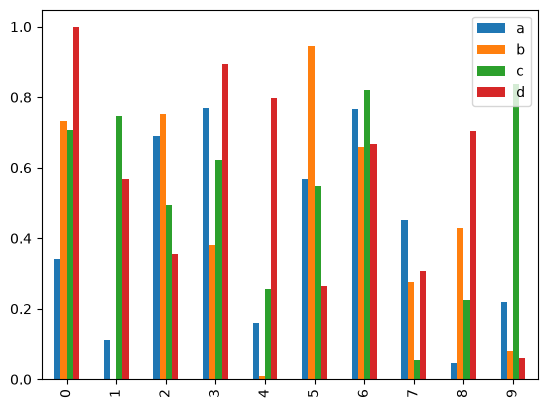

In [116]:
df.plot.bar();  # plot a bar chart of the DataFrame

#### Method 2: Using the `kind="bar"` Parameter
- Functionally identical to `df.plot.bar()`.

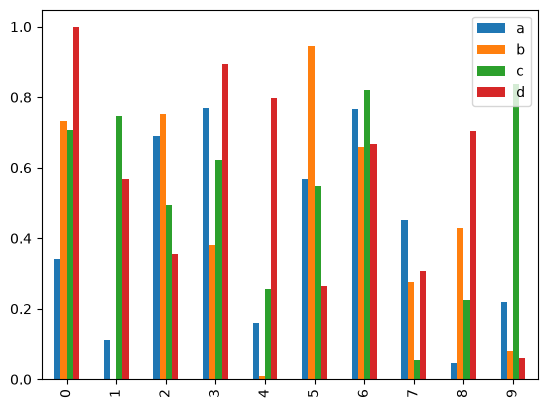

In [117]:
# Plot a bar chart with the kind parameter
df.plot(kind="bar");

Plotting vehicle prices across manufacturers (`Make`):

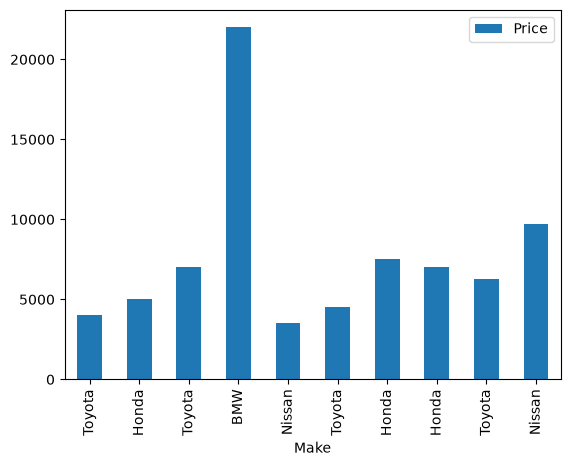

In [118]:
# Plot a bar chart from car_sales DataFrame
car_sales.plot(x="Make", y="Price", kind="bar");

### 3.6 Histograms from DataFrames

Histograms visualize empirical frequency distributions.
Calling `.plot.hist()` on the Series:

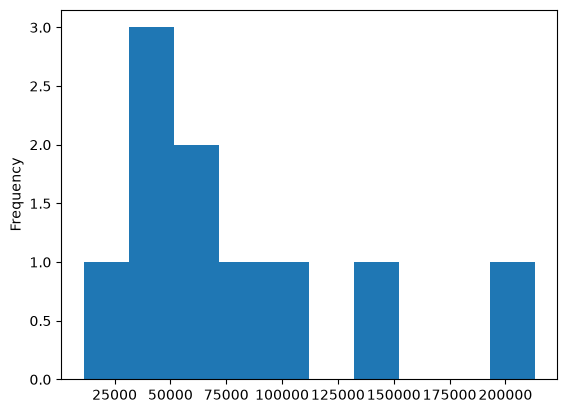

In [119]:
car_sales["Odometer (KM)"].plot.hist();

Equivalent formulation using `kind="hist"` (defaults to 10 bins):

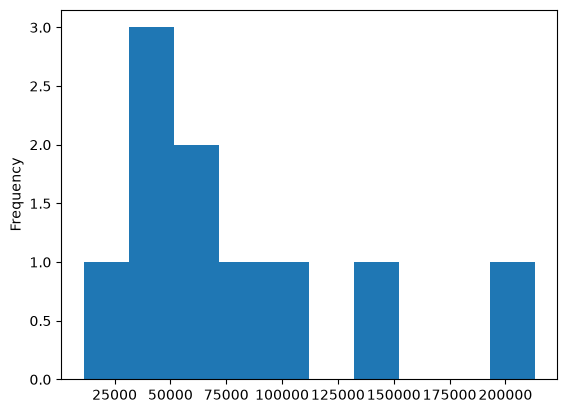

In [120]:
car_sales["Odometer (KM)"].plot(kind="hist");

#### Adjusting Histogram Resolution (`bins=20`)
- **`bins=20`**: Splits the range into 20 equal intervals, revealing finer data groupings.

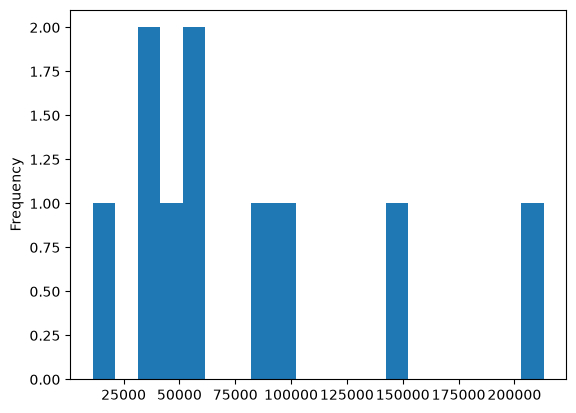

In [121]:
# Change the number of bins in the histogram
car_sales["Odometer (KM)"].plot(kind="hist", bins=20);

Histogram of vehicle prices with 10 bins:

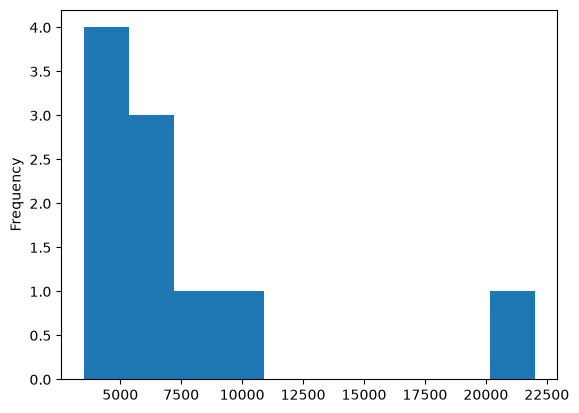

In [122]:
# Create a histogram for price column
car_sales["Price"].plot(kind="hist", bins=10);

### 3.7 Clinical Dataset: Heart Disease Analysis

Loading patient clinical records:
- **`age`**: Patient age in years.
- **`chol`**: Serum cholesterol level in mg/dl.
- **`thalach`**: Maximum heart rate achieved during stress test.
- **`target`**: Diagnosis (`0` = healthy / no heart disease, `1` = heart disease present).

In [123]:
# Import the heart disease dataset
heart_disease = pd.read_csv("data/heart-disease.csv") 
heart_disease

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


Visualizing patient age distribution with high granularity (`bins=50`):
- Shows that the majority of clinic patients are between 40 and 65 years old.

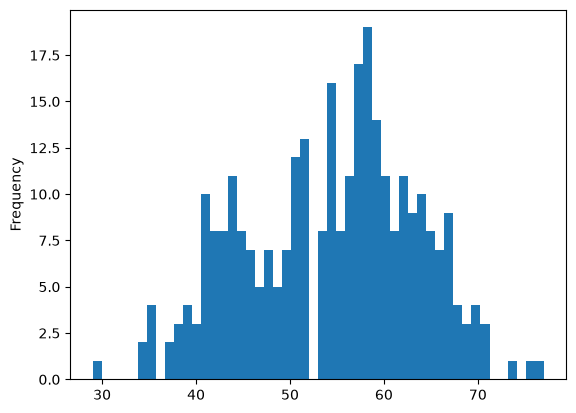

In [124]:
# Create a histogram with the age column
heart_disease["age"].plot.hist(bins=50);

### 3.8 Automated Multi-Panel Histograms (`subplots=True`)

Inspecting feature columns before multi-panel plotting:

In [125]:
# Inspect the data
heart_disease.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


**Method:** `df.plot.hist(subplots=True, figsize=(5, 20))`

**Parameters & Effects:**
- **`subplots=True`**: Generates a dedicated sub-Axes for each numeric column in the DataFrame.
- **`figsize=(5, 20)`**: Aspect ratio specifying 5 inches wide by 20 inches tall to accommodate 14 vertically stacked subplots.
- **Takeaway:** While convenient for rapid overview, automated subplots often suffer from overlapping axis tick labels and inconsistent scales. The Object-Oriented (OO) API is preferred for publication-grade clarity.

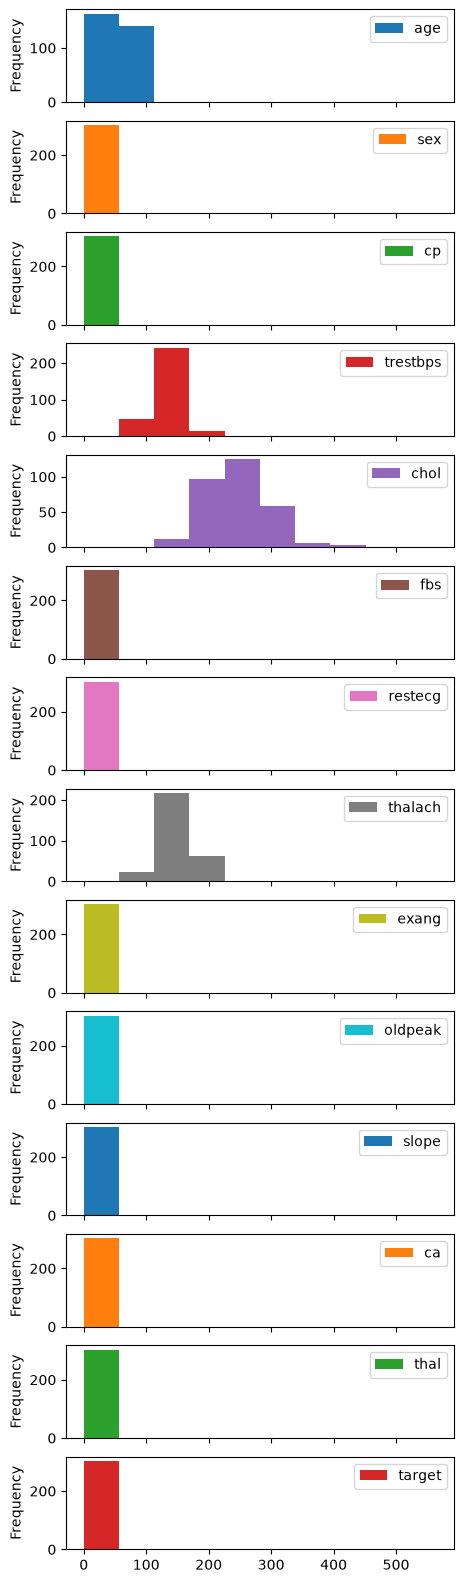

In [126]:
heart_disease.plot.hist(figsize=(5, 20), subplots=True);

## 4. Advanced Object-Oriented Plotting with Matplotlib

When building publication-ready visualizations, combine Pandas boolean indexing for data filtering with Matplotlib's Object-Oriented API for complete layout and aesthetic control.

Filtering the dataset for patients aged over 50:

In [127]:
# Perform data analysis on patient over 50 yrs old
over_50 = heart_disease[heart_disease["age"] > 50]
over_50

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
297,59,1,0,164,176,1,0,90,0,1.0,1,2,1,0
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


### 4.1 Exploratory Scatter Plot with Categorical Color Mapping

**Parameters:**
- **`c="target"`**: Colors each marker according to target diagnosis (`0` vs `1`).
- *Limitation:* Pandas default scatter creates a continuous gradient colorbar on the side rather than a distinct categorical legend, making binary labels ambiguous.

<Axes: xlabel='age', ylabel='chol'>

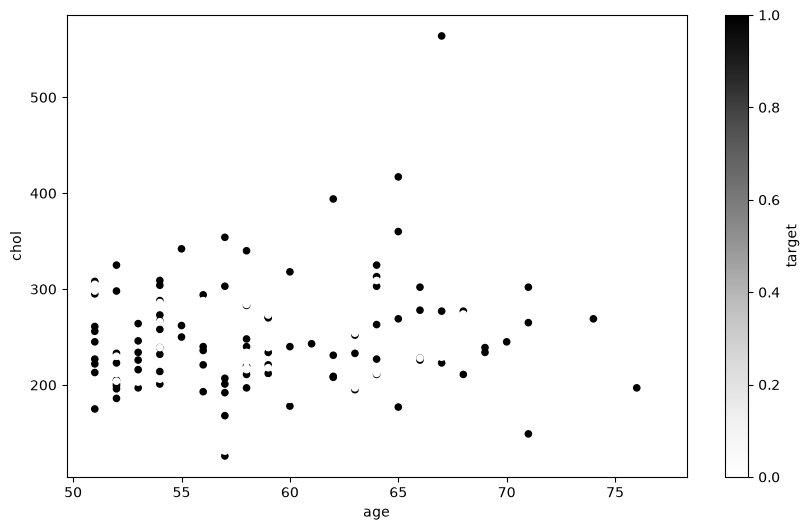

In [128]:
# Create a scatter plot directly from the pandas DataFrame
over_50.plot(x="age",
             y="chol",
             c="target",    # color the points based on the "target" column
             kind="scatter",
             figsize=(10, 6)) # size of the plot

### 4.2 Connecting Pandas Plots to Explicit Axes (`ax=ax`)

Passing an explicitly initialized `ax` object to Pandas `.plot(..., ax=ax)`:
- Integrates Pandas rapid plotting with Object-Oriented canvas sizing and customization.

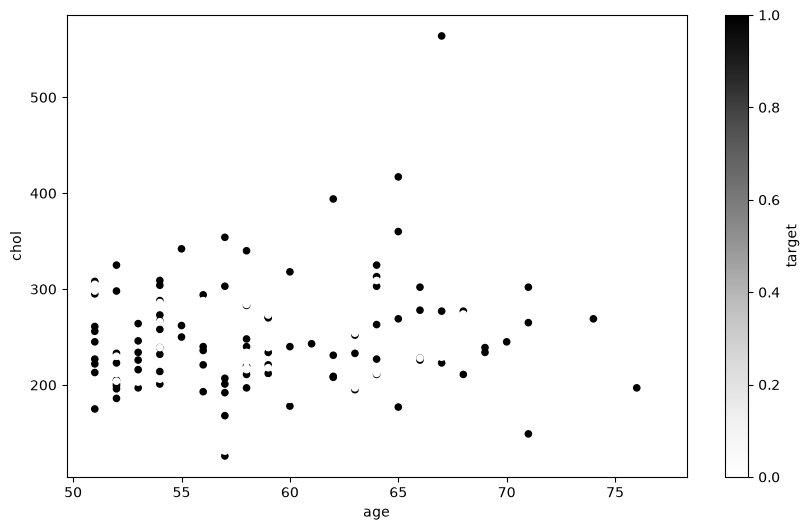

In [129]:
# Create a figure and axes instance
fig, ax = plt.subplots(figsize=(10, 6))  # Create a figure and a set of subplots with specified size

# Plot data on the axes
over_50.plot(x="age",
             y="chol",
             c="target",    # color the points based on the "target" column
             kind="scatter",
             ax=ax);        # specify the axes to plot on

### 4.3 Pure Object-Oriented Scatter Plot with Categorical Legends

**Key Techniques:**
1. `scatter = ax.scatter(x, y, c=classes)`: Returns a `PathCollection` object.
2. `*scatter.legend_elements()`: Dynamically extracts unique marker colors and class labels (`0` and `1`) from the scatter plot.
3. `ax.legend(*scatter.legend_elements(), title="Target")`: Creates a clean, formatted classification legend.

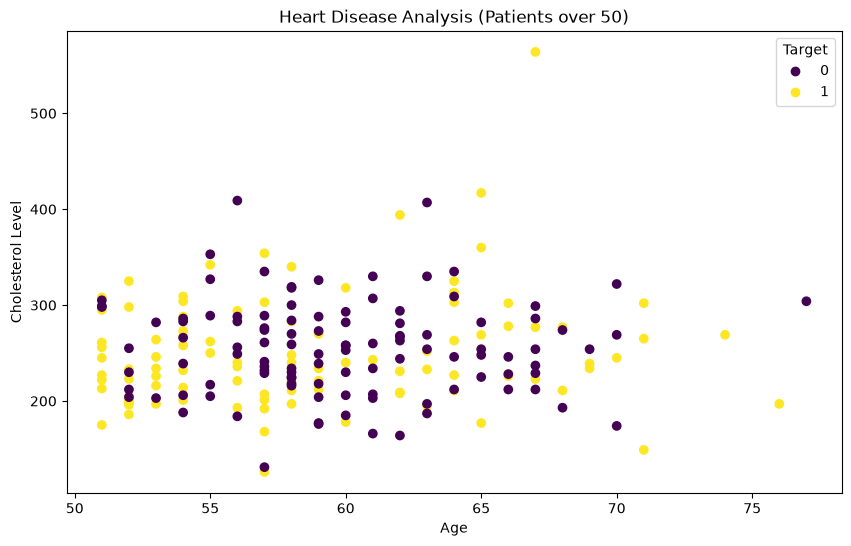

In [130]:
# Create figure and Axes instances
fig, ax = plt.subplots(figsize=(10, 6))  # Create a figure and a set of subplots with specified size

# Plot data directly to the axes
scatter = ax.scatter(over_50["age"], over_50["chol"], c=over_50["target"])

# customize the plot
ax.set(title="Heart Disease Analysis (Patients over 50)",
       xlabel="Age",
       ylabel="Cholesterol Level");

# Setup the legend
ax.legend(*scatter.legend_elements(),
          title="Target");

### 4.4 Adding Statistical Baseline Reference Lines (`ax.axhline`)

**Method:** `ax.axhline(y=..., linestyle="--", color="red")`

**Parameters & Effects:**
- **`y`**: Horizontal coordinate where the benchmark line is drawn (here: group mean cholesterol `over_50["chol"].mean()`).
- **`linestyle="--"`**: Dashed line styling indicating an analytical benchmark rather than measured patient data.
- **`color="red"`**: High-contrast color highlighting the population threshold.

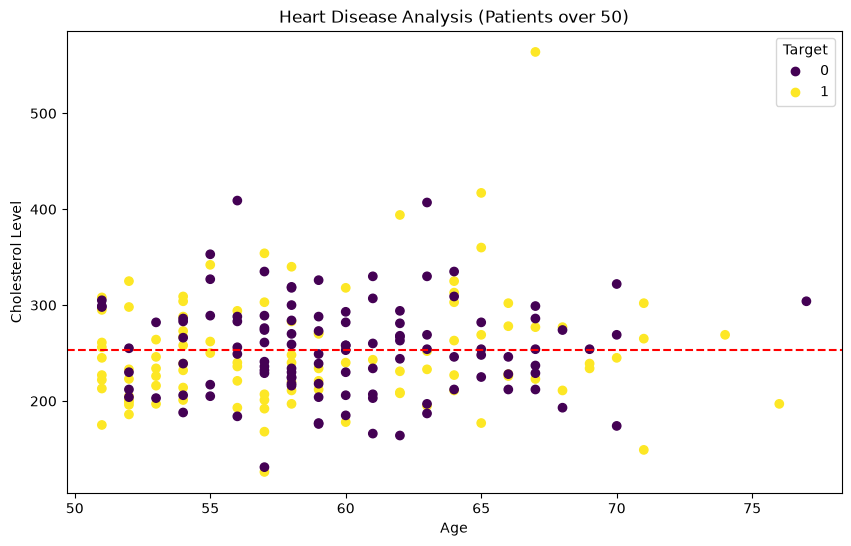

In [131]:
# Create figure and Axes instances
fig, ax = plt.subplots(figsize=(10, 6))  # Create a figure and a set of subplots with specified size

# Plot data directly to the axes
scatter = ax.scatter(over_50["age"], over_50["chol"], c=over_50["target"])

# customize the plot
ax.set(title="Heart Disease Analysis (Patients over 50)",
       xlabel="Age",
       ylabel="Cholesterol Level");

# Setup the legend
ax.legend(*scatter.legend_elements(),
          title="Target");

# add a meanline for cholesterol levels
ax.axhline(over_50["chol"].mean(),
           linestyle="--",
           color="red");

### 4.5 Multi-Panel Dashboard with Shared X-Axis (`sharex=True`)

When comparing multiple clinical features against the same domain (Age), stack subplots vertically and synchronize their horizontal coordinate systems with `sharex=True`.

**Key Architectural Parameters:**
- **`nrows=2, ncols=1`**: 2 vertically stacked subplots.
- **`sharex=True`**: Links the horizontal axes. Panning, zooming, or setting limits on one subplot automatically synchronizes the other, and suppresses redundant middle x-axis labels.
- **`fig.suptitle(t, fontsize, fontweight)`**: Binds a master figure title at the top of the canvas, distinct from individual axes titles (`ax.set_title()`).

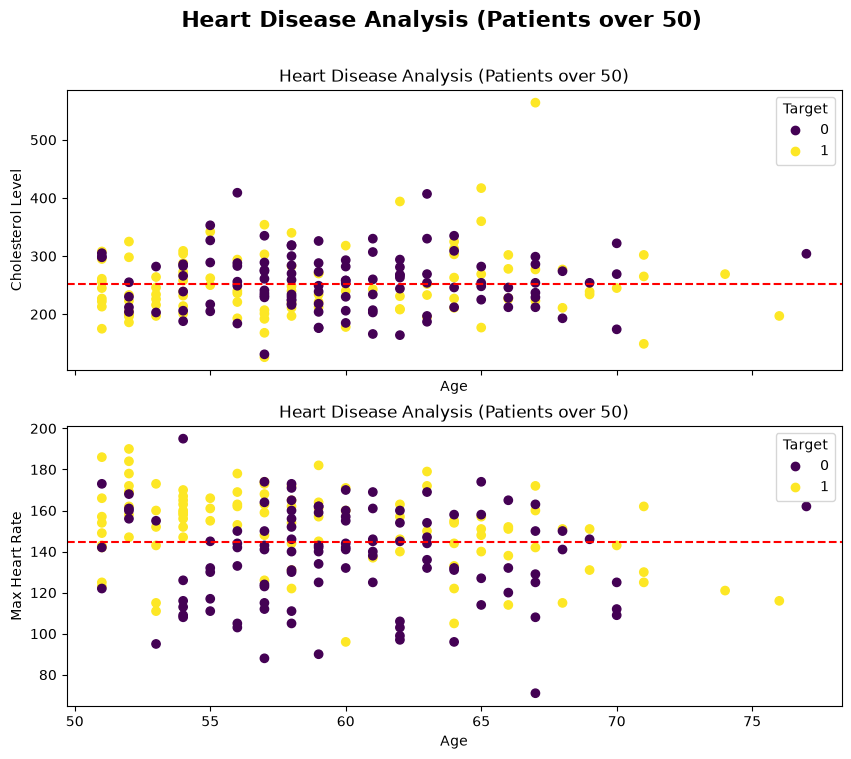

In [132]:
# Setup plot
fig, (ax0, ax1) = plt.subplots(nrows=2, # 2 rows of subplots
                               ncols=1, # 1 column of subplots
                               figsize=(10, 8),
                               sharex=True)       # both plots should share the same x-axis

# --------------------------- Axis 0: Heart Disease and Cholesterol Levels ---------------------------
# Plot data directly to the axes
scatter = ax0.scatter(over_50["age"], over_50["chol"], c=over_50["target"])

# customize the plot
ax0.set(title="Heart Disease Analysis (Patients over 50)",
       xlabel="Age",
       ylabel="Cholesterol Level");

# Setup the legend
ax0.legend(*scatter.legend_elements(),
          title="Target");

# add a meanline for cholesterol levels
ax0.axhline(over_50["chol"].mean(),
           linestyle="--",
           color="red",
           label="Mean Cholesterol Level");

# --------------------------- Axis 1: Heart Disease and Max Heart Rate ---------------------------

# Add data for ax1
scatter2 = ax1.scatter(over_50["age"],
                       over_50["thalach"],
                       c=over_50["target"])

# Customize the plot
ax1.set(title="Heart Disease Analysis (Patients over 50)",
        xlabel="Age",
        ylabel="Max Heart Rate");

# Setup the legend
ax1.legend(*scatter2.legend_elements(),
           title="Target");

# Setup a meanline for max heart rate
ax1.axhline(over_50["thalach"].mean(),
            linestyle="--",
            color="red",
            label="Mean Max Heart Rate");

# Title the figure
fig.suptitle("Heart Disease Analysis (Patients over 50)", fontsize=16, fontweight="bold");

## 5. Plot Customization & Aesthetic Styling

Matplotlib provides comprehensive styling controls including global theme style sheets, typography, axis limits, and continuous/discrete colormaps.

### 5.1 Matplotlib Built-In Style Sheets

Listing all pre-packaged style sheets available in the current environment:

In [133]:
# Check the available styles
plt.style.available

['Solarize_Light2',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'petroff6',
 'petroff8',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

Baseline plot rendered under the default standard style:

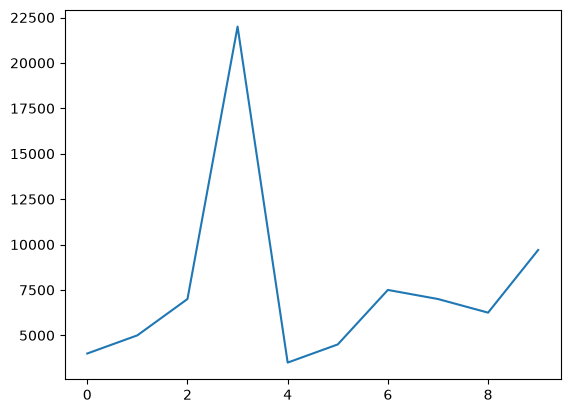

In [134]:
# Plot befor changing style
car_sales["Price"].plot();

### 5.2 Applying Stylesheets (`plt.style.use`)

Activating the `'seaborn-v0_8-whitegrid'` theme:
- Adds subtle white background gridlines, clean muted axis spines, and balanced typography.

In [135]:
# Change the style of our future plots
plt.style.use("seaborn-v0_8-whitegrid")

Plotting under the `'seaborn-v0_8-whitegrid'` theme:

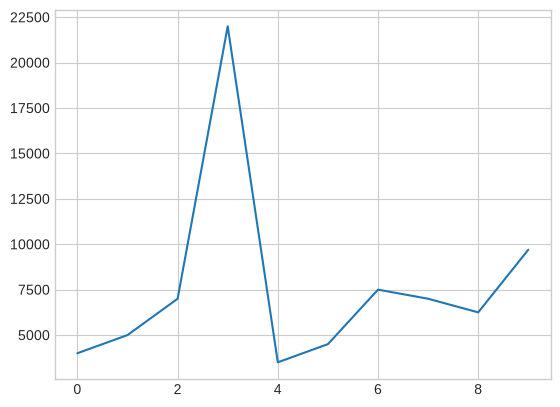

In [136]:
# Plot again
car_sales["Price"].plot();

Activating the `'ggplot'` stylesheet (emulating R's popular ggplot2 library):
- Features light gray plot background, bold white gridlines, and distinctive color palette.

In [137]:
# Change the style to "ggplot"
plt.style.use("ggplot")

Line plot rendered under `'ggplot'`:

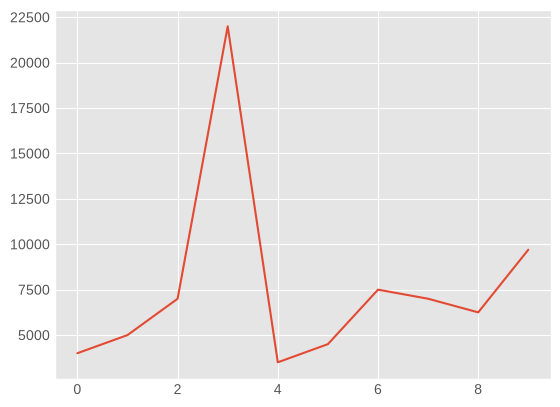

In [138]:
car_sales["Price"].plot();

Scatter plot rendered under `'ggplot'`:

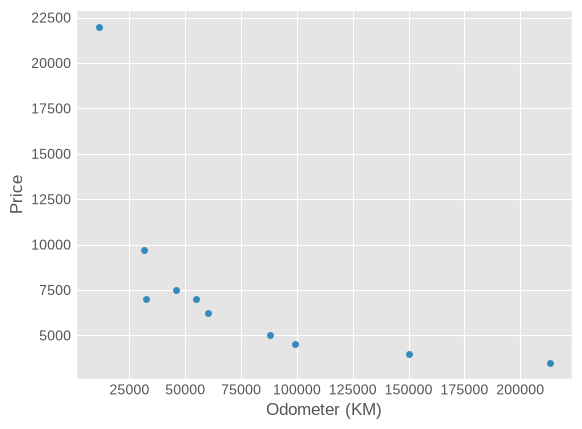

In [139]:
car_sales.plot(x="Odometer (KM)", y="Price", kind="scatter");

Histogram rendered under `'ggplot'`:

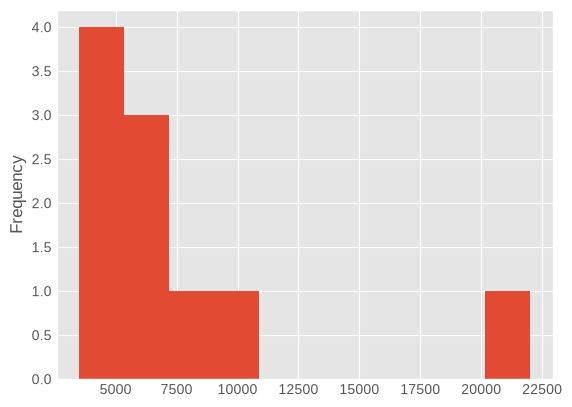

In [140]:
car_sales["Price"].plot.hist();

Resetting global styles back to default:

In [141]:
# Change the style to default
plt.style.use("default")

Confirming restoration of standard Matplotlib defaults:

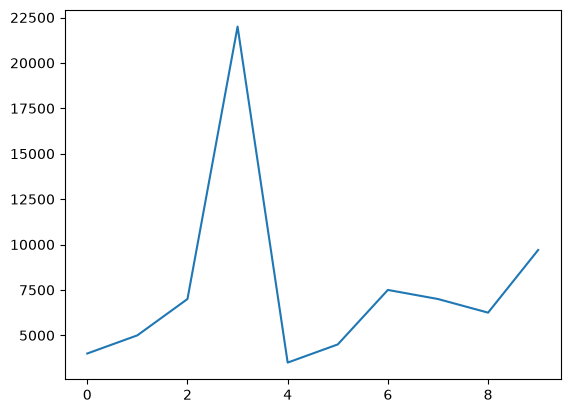

In [142]:
car_sales["Price"].plot();

### 5.3 Customizing Titles, Labels, and Legend Positioning

Generating random data for styling demonstration:

In [147]:
# Create a random data
x = np.random.randn(10, 4)
x

array([[-2.32760404, -2.44522749, -0.71586493,  0.88339684],
       [-1.30043986, -0.07633908,  1.43055682, -1.32340858],
       [-0.43835617, -0.74315248,  0.89196758,  0.46387277],
       [ 0.61766085,  2.49641706,  1.62947522, -0.0990447 ],
       [-0.20199196, -1.44882589, -1.71416469, -0.04964157],
       [-1.29939546,  0.62535543, -0.79171929, -0.58294339],
       [-1.55268054,  2.11015352,  0.75882955, -0.70993024],
       [ 0.15114703,  1.32309131, -0.92782507,  1.90659868],
       [-1.03217489, -0.17736148, -1.6503784 , -2.53851113],
       [ 1.01009078,  0.08570209, -1.73386098, -1.64060121]])

Constructing DataFrame:

In [148]:
df = pd.DataFrame(x, columns=["a", "b", "c", "d"])

Displaying DataFrame values:

In [149]:
df

,a,b,c,d
0,-2.327604,-2.445227,-0.715865,0.883397
1,-1.300440,-0.076339,1.430557,-1.323409
2,-0.438356,-0.743152,0.891968,0.463873
3,0.617661,2.496417,1.629475,-0.099045
4,-0.201992,-1.448826,-1.714165,-0.049642
5,-1.299395,0.625355,-0.791719,-0.582943
6,-1.552681,2.110154,0.758830,-0.709930
7,0.151147,1.323091,-0.927825,1.906599
8,-1.032175,-0.177361,-1.650378,-2.538511
9,1.010091,0.085702,-1.733861,-1.640601


### 5.4 Accessing the Axes Object from Pandas Plots

Assigning the return value of `df.plot()` to `ax`:
- Returns an `AxesSubplot` object, allowing full access to all Object-Oriented Matplotlib methods.

matplotlib.axes._axes.Axes

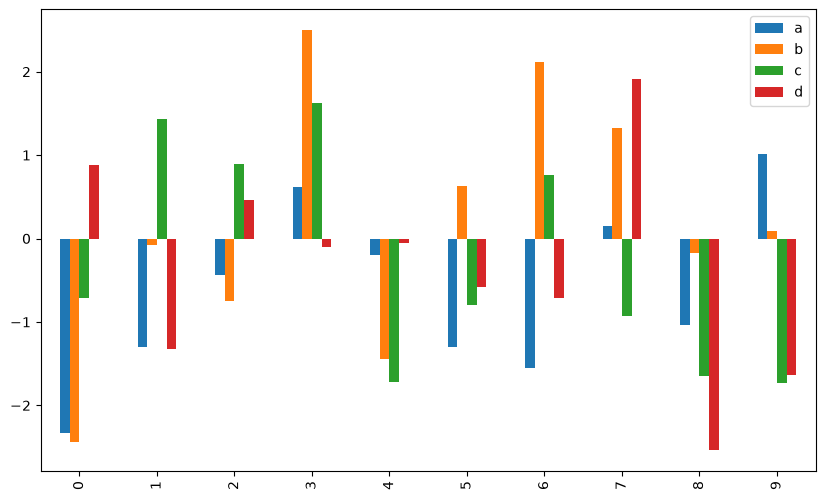

In [150]:
# Create a bar plot
ax = df.plot(kind="bar", figsize=(10, 6))

# check the type of our ax
type(ax)

Configuring title and axis labels using composite method `ax.set()`:
- `ax.set(title=..., xlabel=..., ylabel=...)` simultaneously sets all three text attributes in a single statement.

[Text(0.5, 1.0, 'Random Bar Plot'),
 Text(0.5, 0, 'Row Number'),
 Text(0, 0.5, 'Random Number')]

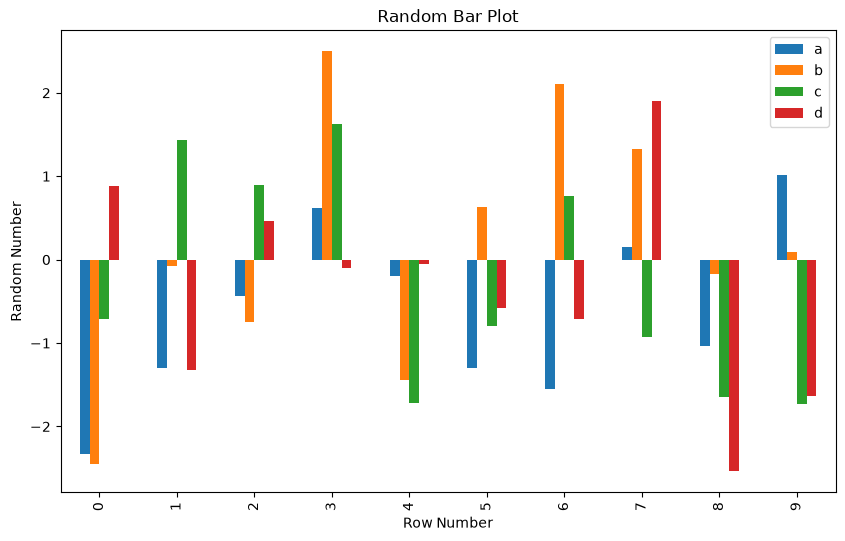

In [152]:
# recreate the ax object
ax = df.plot(kind="bar", figsize=(10, 6))

# Set various attributes
ax.set(title="Random Bar Plot", xlabel="Row Number", ylabel="Random Number")

### 5.5 Legend Positioning (`ax.legend(loc=...)`)

**Parameter:** `loc` (location string or integer code)
- **`loc="upper left"`**: Explicitly anchors the legend in the upper-left quadrant to prevent occluding data bars.
- Available location options: `'best'` (auto-detects empty space), `'upper right'`, `'upper left'`, `'lower left'`, `'lower right'`, `'center'`.

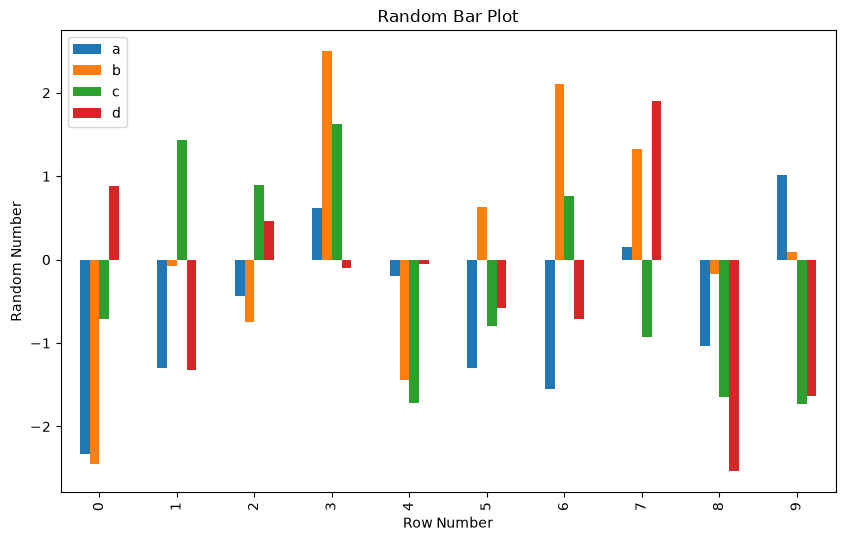

In [153]:
# recreate the ax object
ax = df.plot(kind="bar", figsize=(10, 6))

# Set various attributes
ax.set(title="Random Bar Plot", xlabel="Row Number", ylabel="Random Number")

# Change the legend position
ax.legend(loc="upper left");

### 5.6 Color Maps (`cmap`)

Colormaps map continuous numerical values or categorical codes to smoothly graduated color palettes.

**Popular Colormap Families:**
- **Perceptually Uniform**: `'viridis'` (default), `'plasma'`, `'inferno'`, `'magma'`, `'cividis'`.
- **Sequential / Thematic**: `'winter'`, `'cool'`, `'spring'`, `'autumn'`, `'Blues'`, `'Greens'`.
- **Diverging**: `'coolwarm'`, `'bwr'`, `'seismic'`.

Rendering with the default `'viridis'` colormap:

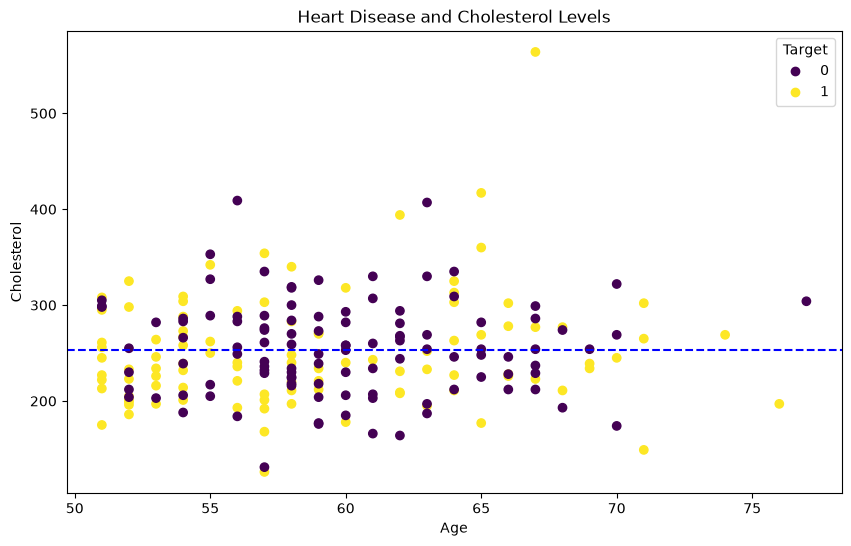

In [154]:

# Setup the Figure and Axes
fig, ax = plt.subplots(figsize=(10, 6))

# Create a scatter plot with no cmap change (use default colormap)
scatter = ax.scatter(over_50["age"], 
                     over_50["chol"], 
                     c=over_50["target"],
                     cmap="viridis") # default cmap value

# Add attributes to the plot
ax.set(title="Heart Disease and Cholesterol Levels",
       xlabel="Age",
       ylabel="Cholesterol");
ax.axhline(y=over_50["chol"].mean(), 
           c='b', 
           linestyle='--', 
           label="Average");
ax.legend(*scatter.legend_elements(), 
          title="Target");

Switching to the `'winter'` colormap (`cmap="winter"`):
- Distinctly separates classes: maps target `0` (healthy) to blue and target `1` (heart disease) to vibrant green.

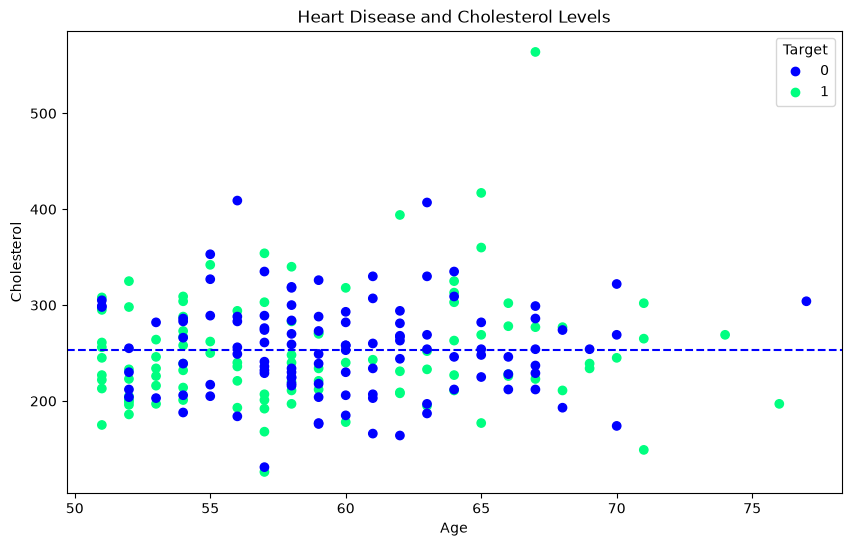

In [155]:

# Setup the Figure and Axes
fig, ax = plt.subplots(figsize=(10, 6))

# Create a scatter plot with no cmap change (use default colormap)
scatter = ax.scatter(over_50["age"], 
                     over_50["chol"], 
                     c=over_50["target"],
                     cmap="winter") # change the colormap to "winter"

# Add attributes to the plot
ax.set(title="Heart Disease and Cholesterol Levels",
       xlabel="Age",
       ylabel="Cholesterol");
ax.axhline(y=over_50["chol"].mean(), 
           c='b', 
           linestyle='--', 
           label="Average");
ax.legend(*scatter.legend_elements(), 
          title="Target");

### 5.7 Fine-Tuning Coordinate Bounds (`xlim` & `ylim`)

By default, Matplotlib auto-scales axis boundaries to tightly enclose observed data points. Manual limit configuration standardizes visual scales and eliminates awkward edge padding.

Baseline multi-panel plot with auto-scaled limits:

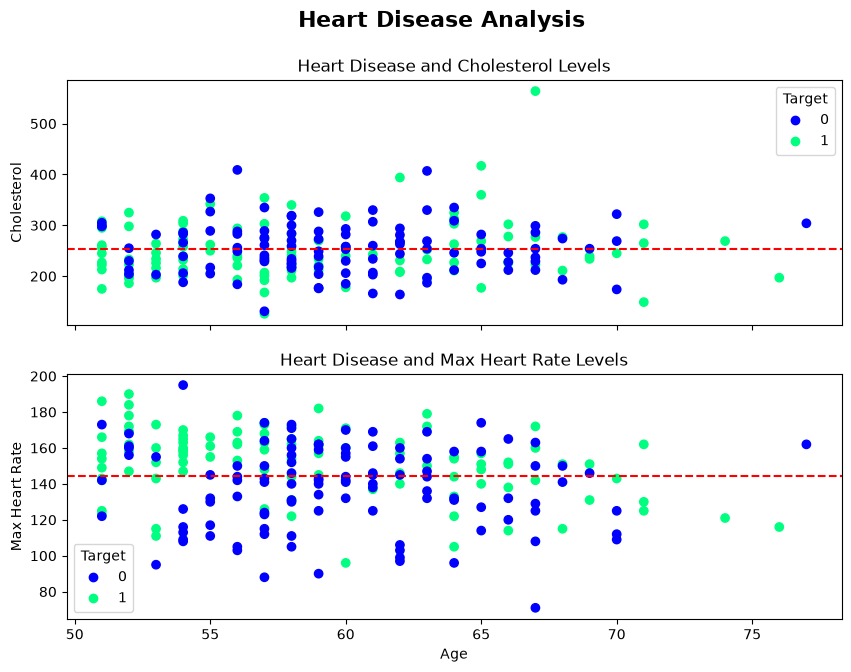

In [156]:
# Recreate double Axes plot from above with colour updates 
fig, (ax0, ax1) = plt.subplots(nrows=2, 
                               ncols=1, 
                               sharex=True, 
                               figsize=(10, 7))

# ---------- Axis 0 ----------
scatter = ax0.scatter(over_50["age"], 
                      over_50["chol"], 
                      c=over_50["target"],
                      cmap="winter")
ax0.set(title="Heart Disease and Cholesterol Levels",
        ylabel="Cholesterol")

# Setup a mean line
ax0.axhline(y=over_50["chol"].mean(), 
            color="r", 
            linestyle="--", 
            label="Average");
ax0.legend(*scatter.legend_elements(), title="Target")

# ---------- Axis 1 ----------
scatter = ax1.scatter(over_50["age"], 
                      over_50["thalach"], 
                      c=over_50["target"],
                      cmap="winter")
ax1.set(title="Heart Disease and Max Heart Rate Levels",
        xlabel="Age",
        ylabel="Max Heart Rate")

# Setup a mean line
ax1.axhline(y=over_50["thalach"].mean(), 
            color="r", 
            linestyle="--", 
            label="Average");
ax1.legend(*scatter.legend_elements(), 
           title="Target")

# Title the figure
fig.suptitle("Heart Disease Analysis", 
             fontsize=16, 
             fontweight="bold");

Applying custom boundaries:
- **`xlim=[50, 100]`**: Restricts patient age axis between 50 and 100. Because `sharex=True` is enabled, both `ax0` and `ax1` are locked to this range simultaneously.
- **`ylim=[60, 220]`**: Scales max heart rate from 60 bpm to 220 bpm.

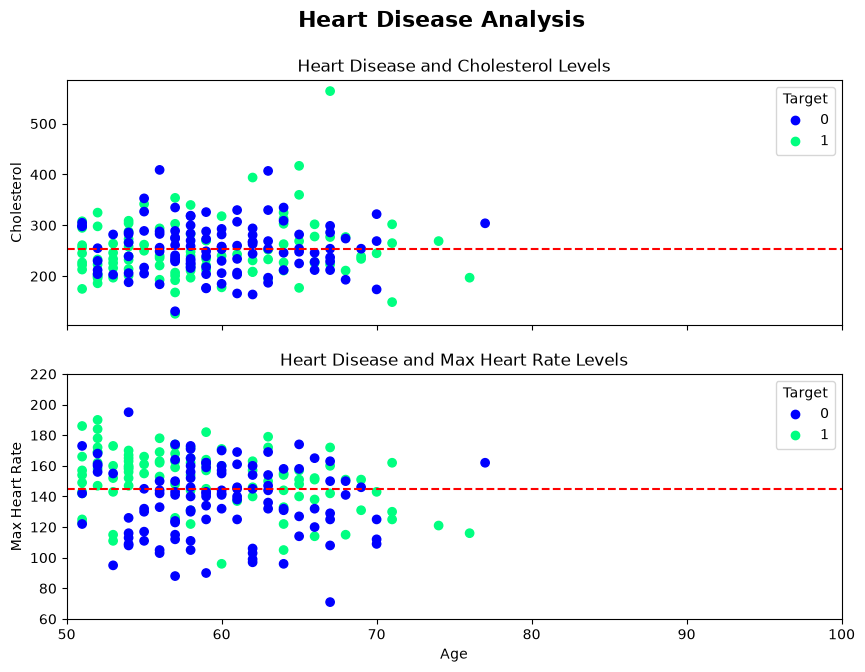

In [157]:
# Recreate double Axes plot from above with colour updates 
fig, (ax0, ax1) = plt.subplots(nrows=2, 
                               ncols=1, 
                               sharex=True, 
                               figsize=(10, 7))

# ---------- Axis 0 ----------
scatter = ax0.scatter(over_50["age"], 
                      over_50["chol"], 
                      c=over_50["target"],
                      cmap="winter")
ax0.set(title="Heart Disease and Cholesterol Levels",
        ylabel="Cholesterol",
        xlim=[50, 100])

# Setup a mean line
ax0.axhline(y=over_50["chol"].mean(), 
            color="r", 
            linestyle="--", 
            label="Average");
ax0.legend(*scatter.legend_elements(), title="Target")

# ---------- Axis 1 ----------
scatter = ax1.scatter(over_50["age"], 
                      over_50["thalach"], 
                      c=over_50["target"],
                      cmap="winter")
ax1.set(title="Heart Disease and Max Heart Rate Levels",
        xlabel="Age",
        ylabel="Max Heart Rate",
        ylim=[60, 220])

# Setup a mean line
ax1.axhline(y=over_50["thalach"].mean(), 
            color="r", 
            linestyle="--", 
            label="Average");
ax1.legend(*scatter.legend_elements(), 
           title="Target")

# Title the figure
fig.suptitle("Heart Disease Analysis", 
             fontsize=16, 
             fontweight="bold");

## 6. Saving and Exporting Figures

Refining age limits to focus tightly on the active patient cohort (`xlim=[50, 80]`):

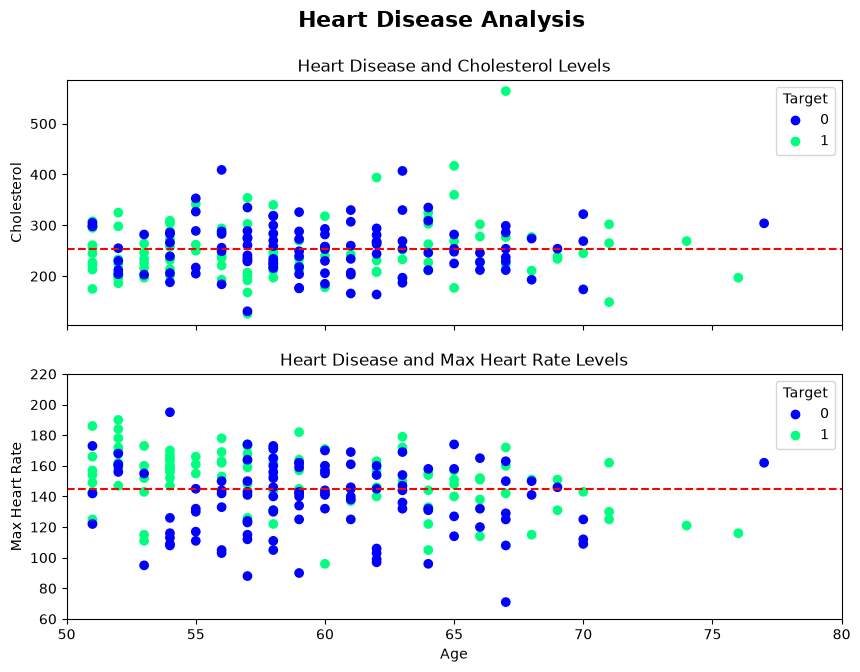

In [158]:
# Recreate the plot from above with custom x and y axis ranges
fig, (ax0, ax1) = plt.subplots(nrows=2, 
                               ncols=1, 
                               sharex=True, 
                               figsize=(10, 7))
scatter = ax0.scatter(over_50["age"], 
                      over_50["chol"], 
                      c=over_50["target"],
                      cmap='winter')
ax0.set(title="Heart Disease and Cholesterol Levels",
        ylabel="Cholesterol",
        xlim=[50, 80]) # set the x-axis ranges 

# Setup a mean line
ax0.axhline(y=over_50["chol"].mean(), 
            color="r", 
            linestyle="--", 
            label="Average");
ax0.legend(*scatter.legend_elements(), title="Target")

# Axis 1, 1 (row 1, column 1)
scatter = ax1.scatter(over_50["age"], 
                      over_50["thalach"], 
                      c=over_50["target"],
                      cmap='winter')
ax1.set(title="Heart Disease and Max Heart Rate Levels",
        xlabel="Age",
        ylabel="Max Heart Rate",
        ylim=[60, 220]) # change the y-axis range

# Setup a mean line
ax1.axhline(y=over_50["thalach"].mean(), 
            color="r", 
            linestyle="--", 
            label="Average");
ax1.legend(*scatter.legend_elements(), 
           title="Target")

# Title the figure
fig.suptitle("Heart Disease Analysis", 
             fontsize=16, 
             fontweight="bold");

### 6.1 Supported Export File Formats

Matplotlib supports both raster and vector output formats:
- **Raster Formats (Pixel-based)**:
  - `png`: Portable Network Graphics (lossless, supports transparency).
  - `jpg` / `jpeg`: Joint Photographic Experts Group (compressed).
- **Vector Formats (Mathematically scaled, infinite resolution without pixelation)**:
  - `pdf`: Portable Document Format (standard for academic papers and publications).
  - `svg`: Scalable Vector Graphics (standard for web interactive graphics and Adobe Illustrator).
  - `eps`: Encapsulated PostScript (standard for LaTeX publishing).

In [159]:
# Check the supported file types for saving figures
fig.canvas.get_supported_filetypes()

{'eps': 'Encapsulated Postscript',
 'gif': 'Graphics Interchange Format',
 'jpg': 'Joint Photographic Experts Group',
 'jpeg': 'Joint Photographic Experts Group',
 'pdf': 'Portable Document Format',
 'pgf': 'PGF code for LaTeX',
 'png': 'Portable Network Graphics',
 'ps': 'Postscript',
 'raw': 'Raw RGBA bitmap',
 'rgba': 'Raw RGBA bitmap',
 'svg': 'Scalable Vector Graphics',
 'svgz': 'Scalable Vector Graphics',
 'tif': 'Tagged Image File Format',
 'tiff': 'Tagged Image File Format',
 'webp': 'WebP Image Format',
 'avif': 'AV1 Image File Format'}

Referencing the stored Figure object `fig` renders the entire cached canvas:

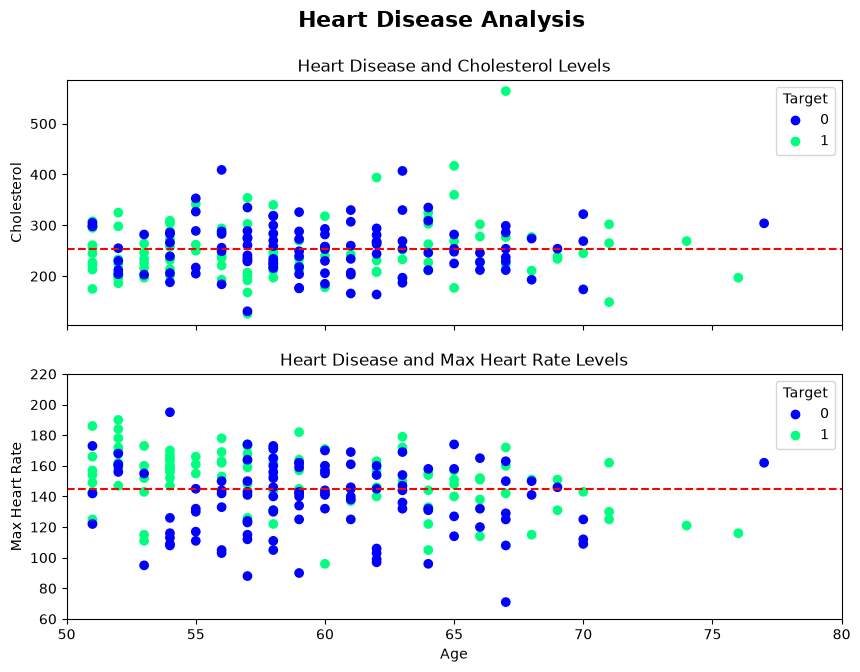

In [160]:
fig

### 6.2 Exporting Figures with `fig.savefig()`

**Method:** `fig.savefig(fname, dpi=None, bbox_inches=None, transparent=False)`

**Parameters & Effects:**
- **`fname`**: Target destination file path. Format is inferred automatically from file extension (`.png`, `.pdf`, `.svg`).
- **`dpi=300`** (Dots Per Inch): Resolution setting for raster images. Standard screen display is 72–100 DPI; publication print standard is **300 DPI**.
- **`bbox_inches="tight"`** (Recommended): Automatically computes bounding box to prevent clipping titles, axis labels, or rotated tick marks.

In [162]:
# Save the figure
fig.savefig("data/figures/heart-disease-analysis.png", dpi=300)

### 6.3 Standard Reusable Visualization Function Pattern

A clean functional pattern encapsulating the end-to-end visualization pipeline:
1. Ingest & transform raw data.
2. Initialize Figure and Axes with appropriate aspect ratio.
3. Plot geometric layers.
4. Apply aesthetic styling, reference lines, and metadata.
5. Export to disk and return Figure object.

In [163]:

# Potential matplotlib workflow function

def plotting_workflow(data):
    # 1. Manipulate data
    
    # 2. Create plot
    
    # 3. Plot data
    
    # 4. Customize plot
    
    # 5. Save plot
    
    # 6. Return plot
    
    return plot

---

## 7. Comprehensive Matplotlib Quick Guide & Parameter Cheat Sheet

A comprehensive quick-guide reference summarizing all essential Matplotlib functions, methods, parameters, and their visual effects.

### Core Architecture & Figure Setup

| Function / Method | Key Parameters | Default | Description & Visual Effect |
| :--- | :--- | :--- | :--- |
| `plt.subplots()` | `nrows=1, ncols=1, figsize=None, sharex=False, sharey=False` | `1, 1, None, False, False` | Instantiates Figure canvas and grid of sub-Axes. `sharex=True` links horizontal limits and synchronizes zooming. |
| `plt.figure()` | `figsize=None, dpi=None, facecolor=None` | `None, 100, 'white'` | Creates a top-level canvas without subplots. |
| `fig.suptitle()` | `t, fontsize=12, fontweight='normal', y=0.98` | — | Renders a master centered title at the top of the overall Figure canvas. |
| `fig.savefig()` | `fname, dpi='figure', bbox_inches=None, transparent=False` | — | Exports figure to disk. `dpi=300` ensures print resolution; `bbox_inches='tight'` prevents label cropping. |
| `plt.style.use()` | `style` | `'default'` | Applies a global aesthetic stylesheet across all subsequent plots (e.g., `'seaborn-v0_8-whitegrid'`, `'ggplot'`). |
| `plt.show()` | `block=None` | — | Flushes GUI event loop and displays active figure canvas. |

### Axes Plotting Methods (`ax.<method>`)

| Method | Key Parameters | Parameter Details & Effects | Primary Use Case |
| :--- | :--- | :--- | :--- |
| `ax.plot(x, y)` | `color`, `linewidth` (`lw`), `linestyle` (`ls`), `marker`, `markersize` (`ms`), `alpha` | `ls='--'` (dashed), `marker='o'` (circle), `lw=2` (line thickness). | Continuous trendlines, mathematical functions, time-series curves. |
| `ax.scatter(x, y)` | `s` (size), `c` (color array), `cmap` (colormap), `alpha` (opacity), `marker` | `c` accepts numerical or categorical arrays; `alpha=0.5` reduces visual crowding. | Bivariate correlations, clustering, multi-variable comparisons. |
| `ax.bar(x, height)` | `width=0.8`, `color`, `edgecolor`, `align='center'` | `width` controls bar thickness; `color` sets fill tone. | Categorical comparisons with discrete labels. |
| `ax.barh(y, width)` | `height=0.8`, `color`, `align='center'` | Swaps axis orientation; categories align vertically. | Categorical comparisons with long or numerous string labels. |
| `ax.hist(x)` | `bins=10`, `density=False`, `range=None`, `alpha=1.0`, `color` | Higher `bins` reveal fine-grained distribution shape; `density=True` scales to probability density. | Frequency distributions, statistical normality checks. |
| `ax.axhline(y)` | `y=0`, `color`, `linestyle='--'`, `linewidth=1.5`, `label` | Draws a horizontal reference line spanning the full x-domain at position `y`. | Analytical baselines (mean, median, target threshold). |
| `ax.axvline(x)` | `x=0`, `color`, `linestyle='--'`, `linewidth=1.5`, `label` | Draws a vertical reference line spanning the full y-domain at position `x`. | Event markers, timeline milestones, boundary cutoffs. |

### Canvas & Axes Customization (`ax.set`)

| Method / Property | Syntax / Arguments | Description & Visual Effect |
| :--- | :--- | :--- |
| `ax.set()` | `ax.set(title=..., xlabel=..., ylabel=..., xlim=..., ylim=...)` | Composite bulk setter configuring title, axis labels, and coordinate limits simultaneously. |
| `ax.legend()` | `handles, labels, loc='best', title=None, frameon=True` | Generates a legend box. `loc='upper left'` or `'best'` prevents data occlusion; `*scatter.legend_elements()` extracts categorical scatter classes. |
| `ax.set_xlim([min, max])` | List/tuple `[left, right]` | Explicitly sets horizontal axis view boundaries. |
| `ax.set_ylim([min, max])` | List/tuple `[bottom, top]` | Explicitly sets vertical axis view boundaries. |
| `ax.grid()` | `visible=True, which='major', linestyle=':', alpha=0.6` | Displays background grid guide lines. |

### Pandas Plotting Shortcuts (`df.plot(...)`)

| Call Syntax | Underlying Matplotlib Operation | Key Parameters |
| :--- | :--- | :--- |
| `df.plot(x=..., y=...)` | `ax.plot()` | `kind='line'`, `figsize=(w, h)`, `color=...` |
| `df.plot(kind='scatter', x=..., y=..., c=...)` | `ax.scatter()` | `c='col_name'` for data-driven marker coloring. |
| `df.plot(kind='bar')` or `.plot.bar()` | `ax.bar()` | Groups multiple numeric columns into grouped bars automatically. |
| `df.plot(kind='hist', bins=...)` or `.plot.hist()` | `ax.hist()` | `subplots=True` automatically generates individual sub-Axes per numeric column. |